# E101 · Exposed versus unexposed: propensity scores in a brand lift study, graded by the experiment inside it

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: the **Criteo Uplift Prediction Dataset v2.1** (Diemert et al. 2018; CC BY-NC-SA 4.0): **13,979,592 users** of advertising campaigns run as randomised **incrementality tests**, with a test arm (85%) and a holdout that saw no ads, a flag for whether a test user was **actually shown an ad**, two outcomes (a **site visit** and a **conversion**) and twelve anonymised user features. We work on a fixed random sample of **300,000 users** and keep the exact counts for all 14 million |
| **You will learn** | Why "exposed versus unexposed" is the tempting design when no holdout exists, and why exposure is **not random** (standardised mean differences of up to 1.5) · the experiment as the answer key: **intent-to-treat**, one-sided noncompliance and the **Wald / IV estimate of the effect on the exposed** as a Bayesian principal-strata model in PyMC · **checking a randomisation** and adjusting an experiment for a measured imbalance from sufficient statistics · a **Bayesian propensity model** with hierarchical shrinkage on a respondent file that oversamples the exposed (the **case-control** correction), a prior predictive check, **overlap**, a calibration check that fails, **balance** after weighting · four estimators of the effect on the exposed - **IPW**, **stratification**, **outcome regression**, **AIPW** - with posterior uncertainty propagated through a **cut** two-stage posterior and the **Bayesian bootstrap** · why they all miss: the **imputed baseline**, a feature ladder that never tells you when to stop · **sensitivity analysis**: E-values and a confounding-bias parameter in PyMC that the data cannot learn · **survey-sized replays**: noisy-and-right against tight-and-wrong, and how **ghost ads** shrink the experiment's noise |

In [1]:
import os

for v_ in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v_] = "1"  # nutpie runs chains as threads: a BLAS pool per chain would fight over the cores

import itertools
import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
from scipy import special, stats

from pymc_challenges import data

RANDOM_SEED = 101
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
sys.modules.pop("jax", None)  # arviz leaves a lazy jax stub that makes matplotlib import all of JAX
pd.set_option("display.width", 160)
T_START = time.time()

BLUE, ORANGE, AQUA, PURPLE, RED = "#2a78d6", "#eb6834", "#1baf7a", "#8c5ac8", "#c8384e"
INK, MUTED, LIGHT = "#222222", "#8a8984", "#d9d8d3"
KPIS = ["visit", "conversion"]
print(f"PyMC {pm.__version__}, ArviZ {az.__version__}")

PyMC 6.3.2, ArviZ 1.3.0


## The setting

A brand manager has just run a campaign and asks the question every campaign ends with: **did the ads
work, and by how much?** The usual tool is a **brand lift study**. A survey vendor recruits people who saw
the ads and people who did not, asks both groups the same questions (do you know the brand, would you
consider it, do you intend to buy), and reports the difference as the campaign's lift. Done well, the "did
not see the ads" group is a randomised **holdout**: people the platform deliberately kept away from the
campaign. Done the cheap way, it is everyone else - people who simply happened not to be reached - and the
vendor tries to make the two groups comparable after the fact, by matching or weighting on what it knows
about the respondents.

That after-the-fact correction is **propensity score** analysis (Rosenbaum & Rubin 1983): model each
person's probability of being exposed from their characteristics, then compare exposed and unexposed
people who had the same probability. If everything that drives both exposure and the outcome is among the
characteristics, the comparison is as good as an experiment. Advertising is a hard place for that "if".
Ad platforms deliver ads to the people most likely to respond - active users, people who recently visited
the advertiser's site, people already in the market - so exposure is tangled up with intent. Gordon,
Zettelmeyer, Bhargava & Chapsky (2019) tested this directly on 15 large Facebook campaigns that had been run
as randomised experiments: they reran each one as an observational study with Facebook's rich user data,
and the propensity-based methods often **overstated** the lift, in some campaigns several times over. Lewis
& Rao (2015) explained why ad effects are so hard to measure at all: the effect of one campaign on one person
is tiny next to the noise in their behaviour.

This notebook repeats that test on public data. No respondent-level brand lift survey is public, so we use
the closest real thing: Criteo's uplift dataset (Diemert et al. 2018), assembled from **randomised
incrementality tests**. Each user was assigned at random to a test arm, where the campaign could show them
ads, or a control arm, where it could not; the file records whether each test user was **actually shown** an
ad, and what they did over the next two weeks. That gives us both halves of the comparison in one data set:
the observational "exposed versus unexposed" study a vendor would run, and the randomised experiment that
grades it. The brand KPI is a stand-in. Criteo records a **visit** to the advertiser's site and a
**conversion**, not a survey answer. We use the visit as the upper-funnel KPI (it is what consideration
surveys try to measure: did the person engage with the brand) and the conversion as the lower-funnel one, and
we treat each user as a respondent. Nothing in the statistics depends on how the outcome was collected; what
matters is that the people who saw the ads differ from those who did not in ways that also drive the outcome.

C09 asked the same question of a job-training programme with LaLonde's data, and E63 used instrumental
variables for quasi-experiments; here the treatment is an ad, the experiment lives inside the same file, and
we can also replay the study at the size of a real survey.

| part | question | tool |
|---|---|---|
| A | What is in the data? | three cells: control, test-unexposed, test-exposed; the naive comparison |
| B | What does the experiment say? | intent-to-treat, the Wald estimate as a Bayesian principal-strata model; a balance check of the randomisation; regression adjustment from sufficient statistics |
| C | Why is exposure not random? | standardised mean differences; who gets an ad |
| D | Can we model exposure? | a Bayesian propensity model on a respondent file that oversamples the exposed; prior predictive, calibration, overlap, balance |
| E | What do propensity methods say? | IPW, stratification, outcome regression, AIPW, with propagated uncertainty; one figure against the experiment |
| F | Why do they miss? | the imputed baseline; adding features; flexibility |
| G | How strong is the hidden confounder? | E-values; a bias parameter in PyMC |
| H | What happens at survey size? | replayed surveys of 2,000-60,000 respondents; coverage; ghost ads |
| I | What should the brand manager report? | the decision and the next study |

## A · The data

In [2]:
data.describe("e101_criteo_uplift")
raw = np.load(data.path("e101_criteo_uplift"))
cells = ["control", "test, unexposed", "test, exposed"]
full = pd.DataFrame({"users": raw["cell_n"], "visits": raw["cell_visit"], "conversions": raw["cell_conversion"]},
                    index=cells)
full["visit rate"] = full.visits / full.users
full["conversion rate"] = full.conversions / full.users
print(f"\nall {int(raw['n_total']):,} users in the file:")
print(full.to_string(formatters={"users": "{:,}".format, "visits": "{:,}".format, "conversions": "{:,}".format,
                                 "visit rate": "{:.4f}".format, "conversion rate": "{:.5f}".format}))
n_test = full.users.iloc[1:].sum()
print(f"\ntest share {n_test / full.users.sum():.3f}; exposed share of the test arm {full.users.iloc[2] / n_test:.4f}")
for k in KPIS:
    r = full[f"{k} rate"]
    print(f"{k:10s}: exposed {r.iloc[2]:.4f} vs unexposed {r.iloc[1]:.4f} -> difference {r.iloc[2] - r.iloc[1]:+.4f}, "
          f"ratio {r.iloc[2] / r.iloc[1]:.1f}x")

e101_criteo_uplift: npz. A simple random sample of 300,000 of the 13,979,592 users in Criteo's pooled incrementality tests (randomised holdouts; several advertisers' tests sub-sampled to one treatment ratio): X (300000, 12) float32 anonymised features f0-f11 (float64 in the source), treatment (1 = test arm, randomised, ~85%), exposure (1 = the user was actually shown an ad; only possible in test), visit (visited the advertiser's site), conversion, row (row in the source). Plus EXACT full-data counts for the cells control / test-unexposed / test-exposed: cell_n, cell_visit, cell_conversion (3,), and per-cell feature sums cell_xsum, cell_xsq (3, 12); full-data sufficient statistics of a 91-column basis of the features' normal scores (1, r, r^2, pairwise products): basis_zz (arm, 91, 91), basis_zy (arm, outcome, 91), basis_cell_sum (3, 91); n_total, seed. Absolute rates are not the campaign's: Criteo down-sampled negatives non-uniformly.
  source: Criteo Uplift Prediction Dataset v2.1: Di

The campaign file has three cells. **2.1 million** users were held out in control; **11.9 million** were in
the test arm, of whom only **428,212 (3.6%)** were actually shown an ad. The ad server reaches a user only when
they show up somewhere it can bid; most test users never did. No control user was exposed. (The file pools
several advertisers' tests, as part B explains; we treat it as one campaign, as a brand manager's study would.)

The naive brand lift report compares the last two rows: exposed users visited at **41.5%** against 3.5% for
the unexposed, **11.9 times** as often, and converted at 5.4% against 0.12%, **45 times** as often. Those are
the numbers a vendor without a holdout starts from.

For modelling, the cached file holds a fixed random sample of 300,000 users, which keeps the arms'
proportions (85% test, 3.58% of test exposed). The features are anonymised and randomly projected by Criteo, so
they have no names; the table shows they are a mixed bag, from a nearly continuous f0 to an f1 with 25 values,
most with a large point mass at one end.

In [3]:
X = raw["X"].astype(float)
T = raw["treatment"].astype(int)
D = raw["exposure"].astype(int)
Y = {"visit": raw["visit"].astype(float), "conversion": raw["conversion"].astype(float)}
FEATS = [f"f{i}" for i in range(12)]
N = len(T)
print(f"cached random sample: {N:,} users; {T.sum():,} test ({T.mean():.3f}), {(1 - T).sum():,} control; "
      f"{D.sum():,} exposed ({D[T == 1].mean():.4f} of test)")
print(pd.DataFrame({f: [len(np.unique(X[:, j])), *np.round(np.percentile(X[:, j], [0, 50, 90, 100]), 2)]
                    for j, f in enumerate(FEATS)}, index=["distinct", "min", "median", "p90", "max"]).to_string())

cached random sample: 300,000 users; 254,900 test (0.850), 45,100 control; 9,122 exposed (0.0358 of test)
                 f0     f1         f2      f3     f4     f5      f6        f7       f8      f9       f10    f11
distinct  206512.00  25.00  127979.00  306.00  87.00  47.00  799.00  16016.00  1473.00  651.00  12808.00  41.00
min           12.62  10.06       8.21   -5.78  10.28  -7.55  -26.79      4.83     3.64   13.19      5.30  -1.23
median        21.92  10.06       8.21    4.68  10.28   4.12   -2.41      4.83     3.97   13.19      5.30  -0.17
p90           25.99  10.06       8.95    4.68  10.28   4.12    0.29      4.83     3.97   25.24      5.30  -0.17
max           26.75  15.45       9.05    4.68  20.26   4.12    0.29     12.00     3.97   68.15      6.47  -0.17


## B · The answer key: what the experiment says

Call $Z_i$ the arm a user was randomised to ($Z = 1$ test), $D_i$ whether they were actually shown an ad,
and $Y_i$ the outcome. Control users cannot be shown the campaign's ads, so $D = 0$ whenever $Z = 0$: this is
**one-sided noncompliance**. Users fall into two latent types (principal strata; Angrist, Imbens & Rubin 1996):
**compliers**, whom the campaign reaches if they are in the test arm (a share $\pi_c$), and **never-takers**,
whom it would not reach either way. In the test arm we see who is who ($D$); in the control arm we do not.

Randomisation makes the two arms the same mix of types. If being assigned to test matters only through the
ad itself (the **exclusion restriction**: a never-taker in test behaves like one in control), then the
difference in mean outcomes between the arms, the **intent-to-treat** effect, comes entirely from the
compliers:

$$\text{ITT} = \bar Y_{Z=1} - \bar Y_{Z=0} = \pi_c\,\big(p_{c1} - p_{c0}\big),$$

where $p_{c1}$ and $p_{c0}$ are the compliers' outcome rates with and without ads. Dividing by the exposure
rate gives the **Wald** (instrumental-variable) estimate (Bloom 1984) of $p_{c1} - p_{c0}$. Because nobody in
control is exposed, the compliers are exactly the exposed, so this is the **effect on the exposed** - the
average treatment effect on the treated, the quantity the brand manager wants and the one the
exposed-versus-unexposed study claims to measure.

As a Bayesian model (Imbens & Rubin 1997) this is four binomials: the number exposed in test with rate
$\pi_c$, outcomes of exposed test users with rate $p_{c1}$, outcomes of unexposed test users with rate
$p_n$ (never-takers), and outcomes in control with the mixture rate $\pi_c p_{c0} + (1 - \pi_c) p_n$. The
mixture is what identifies $p_{c0}$, **what the exposed would have done without ads** - the number every
method below is really trying to estimate. We fit it twice, to the counts of all 14 million users and to the
300,000-user sample, with flat Beta(1, 1) priors on every rate.

In [4]:
def wald(n_c, y_c, n_t, n_te, y_t):
    """Plug-in Wald (IV) estimate of the effect on the exposed and its large-sample sd."""
    pc, pt_, e = y_c / n_c, y_t / n_t, n_te / n_t
    itt = pt_ - pc
    v_itt = pc * (1 - pc) / n_c + pt_ * (1 - pt_) / n_t
    return itt / e, np.sqrt(v_itt) / e, itt, e


truth_unadj = {}
for k, col in [("visit", "visits"), ("conversion", "conversions")]:
    att, sd, itt, e = wald(full.users.iloc[0], full[col].iloc[0], n_test, full.users.iloc[2], full[col].iloc[1:].sum())
    truth_unadj[k] = att
    print(f"{k:10s}: ITT {itt:+.5f}, exposure rate {e:.4f} -> effect on the exposed {att:.4f} (sd {sd:.4f})")

visit     : ITT +0.01034, exposure rate 0.0360 -> effect on the exposed 0.2870 (sd 0.0041)
conversion: ITT +0.00115, exposure rate 0.0360 -> effect on the exposed 0.0320 (sd 0.0010)


In [5]:
def counts(idx_c, idx_t):
    """Cell counts for the IV model from row indices of control and test users."""
    out = {"n_c": len(idx_c), "n_t": len(idx_t), "n_te": int(D[idx_t].sum())}
    for k in KPIS:
        out[f"y_c_{k}"] = Y[k][idx_c].sum()
        out[f"y_te_{k}"] = Y[k][idx_t][D[idx_t] == 1].sum()
        out[f"y_tu_{k}"] = Y[k][idx_t][D[idx_t] == 0].sum()
    return out


def iv_model(c):
    """Bayesian IV with one-sided noncompliance (Imbens & Rubin 1997): compliers are the users the
    campaign reaches if assigned to test; never-takers are not reached in either arm."""
    with pm.Model(coords={"kpi": KPIS}) as m:
        pi_c = pm.Beta("pi_c", 1.0, 1.0)                         # share of compliers (reachable users)
        p_n = pm.Beta("p_n", 1.0, 1.0, dims="kpi")              # never-takers' rate, same in both arms
        p_c0 = pm.Beta("p_c0", 1.0, 1.0, dims="kpi")            # compliers without ads (control)
        p_c1 = pm.Beta("p_c1", 1.0, 1.0, dims="kpi")            # compliers with ads (test, exposed)
        pm.Binomial("reached", n=c["n_t"], p=pi_c, observed=c["n_te"])
        pm.Binomial("y_te", n=c["n_te"], p=p_c1, observed=[c["y_te_visit"], c["y_te_conversion"]], dims="kpi")
        pm.Binomial("y_tu", n=c["n_t"] - c["n_te"], p=p_n, observed=[c["y_tu_visit"], c["y_tu_conversion"]],
                    dims="kpi")
        pm.Binomial("y_c", n=c["n_c"], p=pi_c * p_c0 + (1 - pi_c) * p_n,
                    observed=[c["y_c_visit"], c["y_c_conversion"]], dims="kpi")
        pm.Deterministic("att", p_c1 - p_c0, dims="kpi")
        pm.Deterministic("lift", p_c1 / p_c0, dims="kpi")
    return m


c_full = {"n_c": int(full.users.iloc[0]), "n_t": int(n_test), "n_te": int(full.users.iloc[2]),
          "y_c_visit": int(full.visits.iloc[0]), "y_te_visit": int(full.visits.iloc[2]),
          "y_tu_visit": int(full.visits.iloc[1]), "y_c_conversion": int(full.conversions.iloc[0]),
          "y_te_conversion": int(full.conversions.iloc[2]), "y_tu_conversion": int(full.conversions.iloc[1])}
idx_c_all, idx_t_all = np.flatnonzero(T == 0), np.flatnonzero(T == 1)
with iv_model(c_full):
    idata_iv_full = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
with iv_model(counts(idx_c_all, idx_t_all)):
    idata_iv = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
for name, idt in [("all 14.0M users", idata_iv_full), ("300k sample", idata_iv)]:
    print(f"--- {name}: divergences {int(idt.sample_stats['diverging'].sum())}, "
          f"warm-up {idt.posterior.attrs.get('tuning_steps')} steps")
    print(az.summary(idt, var_names=["att", "lift", "p_c0", "p_c1"], ci_prob=0.9, round_to=4))
pc1_true = idata_iv_full.posterior["p_c1"].mean(("chain", "draw")).to_series()

--- all 14.0M users: divergences 0, warm-up 400 steps
                    mean      sd  eti90_lb  eti90_ub   ess_bulk   ess_tail   r_hat  mcse_mean  mcse_sd
att[visit]        0.2870  0.0039    0.2805    0.2933  4204.3836  3728.3957  1.0006     0.0001   0.0001
att[conversion]   0.0320  0.0009    0.0305    0.0335  4992.6087  3336.8208  1.0044     0.0000   0.0000
lift[visit]       3.2534  0.0988    3.0937    3.4165  4267.4992  3648.7193  1.0011     0.0015   0.0013
lift[conversion]  2.4702  0.1012    2.3138    2.6406  4815.5624  3314.1550  1.0039     0.0015   0.0014
p_c0[visit]       0.1275  0.0039    0.1212    0.1340  4316.8926  3474.5253  1.0008     0.0001   0.0001
p_c0[conversion]  0.0218  0.0009    0.0204    0.0232  4796.6318  3344.7217  1.0023     0.0000   0.0000
p_c1[visit]       0.4145  0.0008    0.4133    0.4158  5753.3090  3337.8647  1.0021     0.0000   0.0000
p_c1[conversion]  0.0538  0.0003    0.0532    0.0544  5725.7085  3125.0541  1.0014     0.0000   0.0000
--- 300k sample: di

On all users the campaign raised the visit rate in the test arm by **1.03 percentage points** and the
conversion rate by **0.115 points**. Only **3.6%** of test users were shown an ad, so per exposed user these
are large effects: the Wald estimate is **28.7 points** for visits (90% interval 28.1-29.3) and **3.20
points** for conversions (3.05-3.35). Exposed users visited at 41.5%; the model says they would have
visited at **12.75%** without the ads (a lift of 3.25 times), and would have converted at **2.18%** instead
of 5.38% (2.47 times). Compare that with the naive gap between exposed and unexposed users, 38.0 and 5.26
points: the unexposed visited at only 3.49% and converted at 0.12%, far below what the exposed would have
done anyway. Sampling diagnostics are clean (no divergences, r_hat at most 1.005).

On the 300,000-user sample the same model is honest but wide: **30.5 points** (25.9-35.1) for visits and
**3.7 points** (2.7-4.7) for conversions. The width comes from dilution. The arms differ only through the
3.6% who saw an ad, so the experiment has to find a 1-point signal in the visit rate of 255,000 test users
against 45,000 controls, and then scale it up 28 times. We come back to this in part H, because at survey
sizes it decides everything.

### B2 · Check the randomisation before trusting it

An experiment is only an answer key if the randomisation held. The usual check is balance: compare the arms
on characteristics measured before assignment. A standardised mean difference (SMD, the difference in means
divided by the pooled standard deviation; Austin 2009) below 0.1 is the common rule of thumb. Criteo's
features were logged before assignment, and the file stores their exact sums in each cell for all 14 million
users.

In [6]:
xs, xq, cn = raw["cell_xsum"], raw["cell_xsq"], raw["cell_n"][:, None]
mean_full = xs / cn
sd_full = np.sqrt(xq / cn - mean_full ** 2)
pooled = lambda a, b: np.sqrt((sd_full[a] ** 2 + sd_full[b] ** 2) / 2)
mean_test = (xs[1] + xs[2]) / (cn[1] + cn[2])
sd_test = np.sqrt((xq[1] + xq[2]) / (cn[1] + cn[2]) - mean_test ** 2)
smd = pd.DataFrame({"test vs control": (mean_test - mean_full[0]) / np.sqrt((sd_test ** 2 + sd_full[0] ** 2) / 2),
                    "exposed vs unexposed": (mean_full[2] - mean_full[1]) / pooled(2, 1)}, index=FEATS)
print("standardised mean differences, all 14.0M users:")
print(smd.round(3).T.to_string())
print(f"largest |SMD|: test vs control {smd.iloc[:, 0].abs().max():.4f}; "
      f"exposed vs unexposed {smd.iloc[:, 1].abs().max():.2f}")

standardised mean differences, all 14.0M users:
                         f0     f1     f2     f3     f4     f5     f6     f7     f8     f9    f10    f11
test vs control      -0.007  0.024 -0.006 -0.049  0.008 -0.031 -0.040  0.021 -0.022  0.024  0.011 -0.005
exposed vs unexposed -0.852  0.433  0.032 -1.469  0.454 -0.640 -1.389  0.593 -1.019  0.882  0.415 -0.334
largest |SMD|: test vs control 0.0488; exposed vs unexposed 1.47


In [7]:
def normal_scores(A):
    """Rank-based normal scores per column (ties share a rank): heavy tails and point masses become tame."""
    return np.column_stack([stats.norm.ppf((stats.rankdata(a) - 0.5) / len(a)) for a in A.T])


R = normal_scores(X)                                                 # on the whole 300k sample
Q = R ** 2
Zall = np.column_stack([R, Q])
Zall = (Zall - Zall.mean(0)) / Zall.std(0)                           # 24 standardised terms


def fit_map(Z, y, prior_sd=0.5, a0=0.0, a_sd=1.5, iters=60):
    """Posterior mode of a logistic regression with N(a0, a_sd) intercept and N(0, prior_sd) slopes (Newton)."""
    Z1 = np.column_stack([np.ones(len(Z)), Z])
    prec = np.r_[1 / a_sd ** 2, np.full(Z.shape[1], 1 / prior_sd ** 2)]
    mu0 = np.r_[a0, np.zeros(Z.shape[1])]
    b = mu0.copy()
    for _ in range(iters):
        p = special.expit(Z1 @ b)
        g = Z1.T @ (y - p) - prec * (b - mu0)
        H = (Z1 * (p * (1 - p))[:, None]).T @ Z1 + np.diag(prec)
        step = np.linalg.solve(H, g)
        step *= min(1.0, 2.0 / max(np.abs(step).max(), 1e-12))             # damped: never move a log-odds by more than 2
        b += step
        if np.abs(step).max() < 1e-8:
            break
    return b


tst = T == 1
b_exp = fit_map(Zall[tst], D[tst], a0=special.logit(D[tst].mean()))
pe = special.expit(np.column_stack([np.ones(N), Zall]) @ b_exp)        # who WOULD be exposed, from features
dec_e = pd.qcut(pe, 10, labels=False)
nv = Y["visit"] == 0
share = pd.DataFrame({"test share, all": pd.Series(T).groupby(dec_e).mean(),
                      "test share, non-visitors": pd.Series(T[nv]).groupby(dec_e[nv]).mean(),
                      "predicted exposure": pd.Series(pe).groupby(dec_e).mean()})
print("by decile of predicted exposure (300k sample):")
print(share.round(3).T.to_string())
print(f"mean predicted exposure: test {pe[tst].mean():.4f}, control {pe[~tst].mean():.4f}")

by decile of predicted exposure (300k sample):
                              0      1      2      3      4      5      6      7      8      9
test share, all           0.846  0.850  0.848  0.848  0.844  0.848  0.847  0.847  0.851  0.868
test share, non-visitors  0.846  0.850  0.848  0.848  0.844  0.847  0.846  0.846  0.849  0.860
predicted exposure        0.001  0.003  0.004  0.005  0.007  0.008  0.011  0.016  0.046  0.249
mean predicted exposure: test 0.0358, control 0.0310


By the rule of thumb the arms are balanced: the largest SMD is **0.049** (f3), against **1.47** between
exposed and unexposed users. By the standard of 14 million users they are not. With 2.1 million controls,
chance alone would give SMDs of about 0.001, so differences of 0.03-0.05 on f3, f5 and f6 are real, and they
point the same way as the exposed-unexposed differences. The second table shows where they sit. Sorting the
sample by a model's predicted chance of being exposed, the test share is 84.4-85.1% in the bottom nine deciles
and **86.8%** in the top one - the users the campaign tends to reach are over-represented in the test arm. It
is still 86.0% among users who never visited, so this is not an artefact of the outcome. The averaged
predicted exposure is 3.58% in test and 3.10% in control.

The data paper explains a likely cause. The file was built by **assembling several advertisers' tests** with
different treatment ratios, then sub-sampling each to a common 85%, and Criteo also down-sampled negative
labels non-uniformly so that the true incrementality could not be recovered (Diemert et al. 2021). Their own
check, a classifier trying to predict the arm from the features, did not flag the imbalance; 14 million rows
do. Two consequences follow. The absolute rates in this file are not the campaign's real ones, so we read
every effect as an effect *in this file*. And the plain Wald estimate compares a control arm that holds
slightly fewer exposure-prone users, who visit far more, with a test arm that holds slightly more: it
overstates the effect. One assumption we cannot test sits under everything that follows: that Criteo's
down-sampling of negatives did not differ between the arms (or by exposure) given the features. If it did, it
would be selection on the outcome, which no covariate adjustment repairs. The non-visitor check above is
consistent with the assumption but cannot prove it.

### B3 · Adjusting the experiment

The standard remedy in a randomised experiment is **regression adjustment** (Lin 2013): model the outcome on
the pre-assignment features in the control arm, predict what each test user would have done without the
campaign, and compare. The adjusted effect on the exposed is

$$\hat\tau_{\text{adj}} = \frac{\bar Y_{Z=1} - \bar z_{Z=1}^{\top}\hat\beta_{0}}{\bar D_{Z=1}},$$

with $\hat\beta_0$ from a regression of $Y$ on a basis $z(x)$ in control. A linear model in the basis needs only
sums: $Z^\top Z$ and $Z^\top y$ in control and the mean of $z$ in test. The data builder stored them for all
14 million users, for a basis of 91 columns (each feature's rank-based normal score, its square, and all 66
pairwise products). With a flat prior the posterior for $\beta_0$ is Gaussian around least squares, so we
write it down instead of sampling it. Three nested bases show how much the answer depends on the choice.

In [8]:
def basis(Rm):
    """[1, r, r^2, r_i r_j (i < j)]: the 91 columns whose full-data sums the data builder stored."""
    pairs_ = [Rm[:, i] * Rm[:, j] for i in range(12) for j in range(i + 1, 12)]
    return np.column_stack([np.ones(len(Rm)), Rm, Rm ** 2, *pairs_])


def adjusted_att(zz_c, zy_c, y_c, n_c, zbar_t, ybar_t, e, n_t, cols):
    """Effect on the exposed after regression adjustment: a linear model of the outcome fitted on the
    CONTROL arm (flat prior, so its posterior is Gaussian around least squares) predicts what test users
    would have done without ads; the difference, divided by the exposure rate, is the adjusted Wald estimate."""
    A, bvec = zz_c[:cols, :cols], zy_c[:cols]
    beta = np.linalg.solve(A, bvec)
    s2 = (y_c - beta @ bvec) / n_c                                   # residual variance (binary y: y'y = sum y)
    m0 = zbar_t[:cols] @ beta
    v_m0 = s2 * zbar_t[:cols] @ np.linalg.solve(A, zbar_t[:cols])
    return (ybar_t - m0) / e, np.sqrt(v_m0 + ybar_t * (1 - ybar_t) / n_t) / e


zz, zy, zsum = raw["basis_zz"], raw["basis_zy"], raw["basis_cell_sum"]
Zb = basis(R)                                                        # the same basis on the sample rows
ctl = ~tst
truth, truth_sd, rows_adj = {}, {}, []
for kk, (k, col) in enumerate([("visit", "visits"), ("conversion", "conversions")]):
    rows_adj.append({"kpi": k, "adjustment": "none (Wald)", "all users": truth_unadj[k]})
    for name, cols in [("linear", 13), ("+ squares", 25), ("+ squares + interactions", 91)]:
        a_full, s_full = adjusted_att(zz[0], zy[0, kk], full[col].iloc[0], full.users.iloc[0],
                                      (zsum[1] + zsum[2]) / n_test, full[col].iloc[1:].sum() / n_test,
                                      full.users.iloc[2] / n_test, n_test, cols)
        Zc = Zb[ctl]
        a_s, s_s = adjusted_att(Zc.T @ Zc, Zc.T @ Y[k][ctl], Y[k][ctl].sum(), ctl.sum(), Zb[tst].mean(0),
                                Y[k][tst].mean(), D[tst].mean(), tst.sum(), cols)
        rows_adj.append({"kpi": k, "adjustment": name, "all users": a_full, "sd": s_full,
                         "300k sample": a_s, "sd (sample)": s_s})
    truth[k], truth_sd[k] = a_full, s_full                           # the richest adjustment is our benchmark
adj = pd.DataFrame(rows_adj)
print(adj.round(4).to_string(index=False))
# the spread across the three adjusted bases: how well the answer key is known beyond its sampling sd
truth_rng = {k: (adj[(adj.kpi == k) & (adj.adjustment != "none (Wald)")]["all users"].min(),
                 adj[(adj.kpi == k) & (adj.adjustment != "none (Wald)")]["all users"].max()) for k in KPIS}
exp_s = {k: adj[(adj.kpi == k) & (adj.adjustment == "+ squares + interactions")].iloc[0] for k in KPIS}
pc0_true = pd.Series({k: pc1_true[k] - truth[k] for k in KPIS})
print("benchmark: " + "; ".join(f"{k} {truth[k]:.4f} (sd {truth_sd[k]:.4f}), no-ad rate of the exposed "
                               f"{pc0_true[k]:.4f}, lift {pc1_true[k] / pc0_true[k]:.2f}x" for k in KPIS))

       kpi               adjustment  all users     sd  300k sample  sd (sample)
     visit              none (Wald)     0.2870    NaN          NaN          NaN
     visit                   linear     0.2221 0.0037       0.2249       0.0250
     visit                + squares     0.2170 0.0036       0.2209       0.0247
     visit + squares + interactions     0.2117 0.0035       0.2239       0.0242
conversion              none (Wald)     0.0320    NaN          NaN          NaN
conversion                   linear     0.0275 0.0009       0.0318       0.0062
conversion                + squares     0.0282 0.0009       0.0319       0.0062
conversion + squares + interactions     0.0278 0.0009       0.0315       0.0061
benchmark: visit 0.2117 (sd 0.0035), no-ad rate of the exposed 0.2028, lift 2.04x; conversion 0.0278 (sd 0.0009), no-ad rate of the exposed 0.0260, lift 2.07x


Adjustment moves the experiment's answer a long way: from 28.7 to **21.2 points** for visits and from 3.20
to **2.78 points** for conversions, with posterior sds of 0.35 and 0.09. The three bases agree to within one
point for visits (22.2, 21.7, 21.2) and 0.07 points for conversions. The 300,000-user sample gives the same
picture with the noise of its size (22.4 and 3.15, sds 2.4 and 0.6). The features only have to explain a gap
of 0.05 standard deviations between two arms that randomisation made nearly identical, which is a much easier
job than the one the propensity methods face below, where the gap is 1.5 standard deviations. Still, the
adjusted number rests on the features capturing what drove the imbalance, and the visit estimate drifts down
by half a point with each richer basis. We take the richest adjustment, **21.2 points for visits and 2.78 for
conversions**, as the benchmark, and we show the unadjusted 28.7 and 3.20 alongside it in every figure. Under
the benchmark the exposed would have visited at **20.3%** and converted at **2.60%** without ads: lifts of
**2.04 and 2.07 times**.

## C · Why exposure is not random

In [9]:
# who visits among CONTROL users (no ads at all): an "activity" score from the features
b_act = fit_map(Zall[T == 0], Y["visit"][T == 0], a0=special.logit(Y["visit"][T == 0].mean()))
act = np.column_stack([np.ones(N), Zall]) @ b_act
print(f"\nbaseline visit propensity learned on control users, applied to test users:")
for lab, m in [("exposed", tst & (D == 1)), ("unexposed", tst & (D == 0))]:
    print(f"  {lab:9s}: mean predicted no-ad visit rate {special.expit(act[m]).mean():.4f}")
dec = pd.qcut(act[tst], 10, labels=False)
by_dec = pd.DataFrame({"exposed share": pd.Series(D[tst]).groupby(dec).mean(),
                       "predicted visit rate": pd.Series(special.expit(act[tst])).groupby(dec).mean()})
print(by_dec.round(4).T.to_string())


baseline visit propensity learned on control users, applied to test users:
  exposed  : mean predicted no-ad visit rate 0.1664
  unexposed: mean predicted no-ad visit rate 0.0358
                           0       1       2       3       4       5       6       7       8       9
exposed share         0.0067  0.0061  0.0056  0.0064  0.0100  0.0435  0.0206  0.0329  0.0723  0.1539
predicted visit rate  0.0012  0.0017  0.0019  0.0020  0.0021  0.0023  0.0048  0.0151  0.0604  0.3129


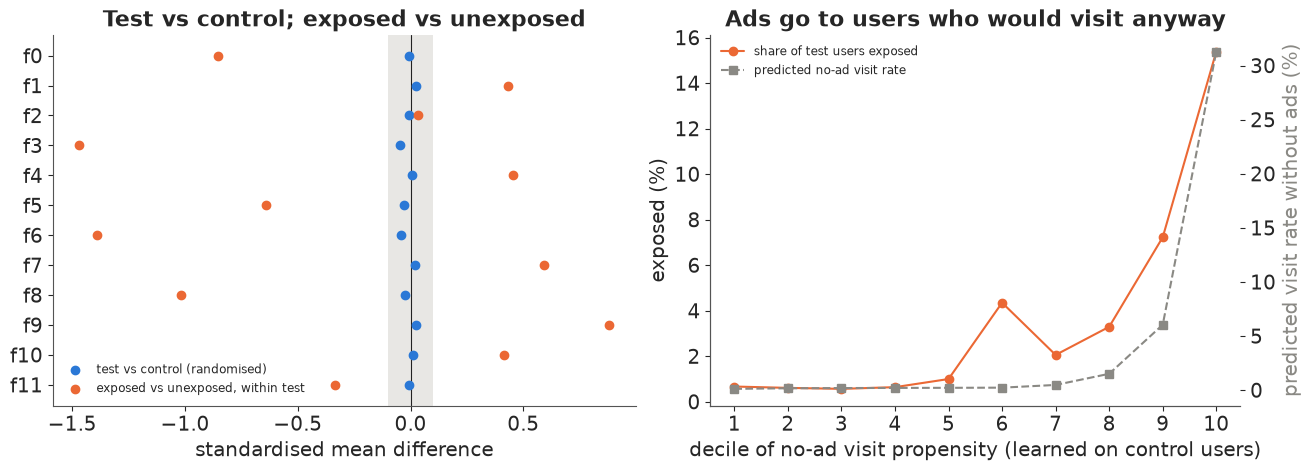

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
yy = np.arange(12)
ax.axvspan(-0.1, 0.1, color=LIGHT, alpha=0.6, lw=0)
ax.scatter(smd.iloc[:, 0], yy, color=BLUE, s=36, label="test vs control (randomised)", zorder=3)
ax.scatter(smd.iloc[:, 1], yy, color=ORANGE, s=36, label="exposed vs unexposed, within test", zorder=3)
ax.set(yticks=yy, yticklabels=FEATS, xlabel="standardised mean difference", ylim=(-0.7, 11.7),
       title="Test vs control; exposed vs unexposed")
ax.axvline(0, color=INK, lw=0.8)
ax.legend(loc="lower left", fontsize=8.5)
ax.invert_yaxis()
ax = axes[1]
ax.plot(by_dec.index + 1, by_dec["exposed share"] * 100, "o-", color=ORANGE, label="share of test users exposed")
ax.set(xlabel="decile of no-ad visit propensity (learned on control users)", ylabel="exposed (%)",
       title="Ads go to users who would visit anyway", xticks=range(1, 11))
ax2 = ax.twinx()
ax2.plot(by_dec.index + 1, by_dec["predicted visit rate"] * 100, "s--", color=MUTED, label="predicted no-ad visit rate")
ax2.set_ylabel("predicted visit rate without ads (%)", color=MUTED)
ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8.5);

The left panel puts the two comparisons side by side on the same scale. Between the randomised arms every
SMD is inside the grey band of $\pm 0.1$; between exposed and unexposed users, eleven of twelve features are
outside it, five of them by more than 0.8 standard deviations. Exposed users are a different population.

The right panel shows what kind of difference. We fit a logistic model of visiting to the **control** arm,
where nobody saw an ad, so its prediction is a user's no-ad visit propensity: a measure of how active and
interested they already are. Applied to test users, it predicts a no-ad visit rate of **16.6%** for those
who were later exposed and **3.6%** for those who were not. Ranking test users by it, the share exposed is
at most 1% in the bottom half and **15.4%** in the top decile. The campaign delivers its ads to the users who
would have visited anyway. (The bump at the sixth decile is probably a point mass in the features: many
users share the same values, so the decile cuts cannot split them.) That is the selection the propensity
methods must undo, and the visit rate of the unexposed (3.5%) says nothing about what the exposed would have
done.

## D · A Bayesian propensity model for exposure

### D1 · The respondent file

A vendor's survey file is not a random sample of the audience: it fills a quota of exposed respondents and
a quota of unexposed ones. We mimic that by keeping every exposed test user in the sample and one unexposed
test user in five. Such **choice-based** sampling changes the exposure rate in the file, but in a logistic
model it changes only the intercept: if unexposed users are kept with probability $f$,

$$\operatorname{logit} P(D = 1 \mid x, \text{in file}) = \operatorname{logit} P(D = 1 \mid x) - \log f$$

(Prentice & Pyke 1979). We fit the model on the file and add $\log f$ back to get each user's propensity in
the population. For the effect on the exposed the correction cancels anyway: unexposed respondents are
weighted by the odds $e(x)/(1 - e(x))$ times $1/f$ for the sampling, and that product is exactly the
odds the model predicts in the file.

In [11]:
F_UNEXP = 0.2
keep = tst & ((D == 1) | (rng.random(N) < F_UNEXP))
S = np.flatnonzero(keep)                         # the respondent file: all exposed + 1 in 5 unexposed, test arm
Zs, Ds = Zall[S], D[S]
Ys = {k: Y[k][S] for k in KPIS}
print(f"respondent file: {len(S):,} rows = {Ds.sum():,} exposed + {(1 - Ds).sum():,} unexposed "
      f"(sampling fraction {F_UNEXP} for the unexposed)")
for k in KPIS:
    print(f"  {k:10s}: {int(Ys[k][Ds == 1].sum()):5d} among exposed, {int(Ys[k][Ds == 0].sum()):5d} among unexposed")

respondent file: 58,161 rows = 9,122 exposed + 49,039 unexposed (sampling fraction 0.2 for the unexposed)
  visit     :  3705 among exposed,  1682 among unexposed
  conversion:   514 among exposed,    63 among unexposed


### D2 · The model and its prior

The twelve features are awkward: f0 has 206,512 distinct values while f1 has 25, and most of them have a
large point mass at one end and a long tail. We replace each by its **rank-based normal score** (ties share
a rank), so a coefficient means the same thing for every feature, and we let each feature act through a
linear and a quadratic term:

$$\operatorname{logit} P(D_i = 1) = a + \sum_j \beta_j\, r_{ij} + \sum_j \gamma_j\,(r_{ij}^2)^\ast,
\qquad \beta_j \sim N(0, 0.5),\quad \gamma_j \sim N(0, \tau_q),\quad \tau_q \sim \text{HalfNormal}(0.5),$$

with every column standardised. The quadratic terms share a scale $\tau_q$ learned from the data, so the
model can switch curvature off as a group (a small hierarchical touch), and $a \sim N(\operatorname{logit}
\bar D_{\text{file}}, 1)$. The slopes' prior is deliberately modest: twelve standardised features with
N(0, 1) slopes would put many users at propensities of 0 or 1 before seeing any data. We check what this prior
implies for the population propensity by pushing prior draws through the design.

In [12]:
coords = {"feature": FEATS}
share = Ds.mean()


def propensity_model(Z, d):
    with pm.Model(coords=coords) as m:
        a = pm.Normal("a", special.logit(share), 1.0)
        b_lin = pm.Normal("b_lin", 0.0, 0.5, dims="feature")
        tau_q = pm.HalfNormal("tau_q", 0.5)
        b_quad = pm.Normal("b_quad", 0.0, tau_q, dims="feature")
        eta = a + Z[:, :12] @ b_lin + Z[:, 12:] @ b_quad
        pm.Bernoulli("exposed", logit_p=eta, observed=d)
    return m


prop_model = propensity_model(Zs, Ds)
with prop_model:
    prior = pm.sample_prior_predictive(draws=500, var_names=["a", "b_lin", "b_quad"], random_seed=RANDOM_SEED)
pa = prior.prior["a"].values.ravel()
pb = np.concatenate([prior.prior["b_lin"].values.reshape(-1, 12), prior.prior["b_quad"].values.reshape(-1, 12)], 1)
sub = rng.choice(len(Zs), 4000, replace=False)
eta_prior = pa[:, None] + pb @ Zs[sub].T + np.log(F_UNEXP)          # population propensity, logit scale
e_prior = special.expit(eta_prior)
print(f"prior predictive, population propensity: median {np.median(e_prior):.3f}; "
      f"share of users below 0.001 {np.mean(e_prior < 1e-3):.2f}, above 0.5 {np.mean(e_prior > 0.5):.2f}; "
      f"implied exposure rate 5-95%: {np.percentile(e_prior.mean(1), [5, 95]).round(3)}")

prior predictive, population propensity: median 0.039; share of users below 0.001 0.06, above 0.5 0.08; implied exposure rate 5-95%: [0.029 0.292]


The prior predictive puts the median user's propensity at 0.04, with 6% of users below 0.001 and 8%
above 0.5, and an implied campaign-wide exposure rate anywhere between 3% and 29%. That is wide but not
absurd: it allows extreme propensities without insisting on them. We sample with nutpie and a low-rank mass
matrix (the 26 parameters are correlated through the features), and with 400 warm-up and 500 kept draws per
chain instead of the default 1,000, because the 58,000-row likelihood is the slowest step in the notebook and
the effective sample sizes below are ample.

In [13]:
t0 = time.time()
with prop_model:
    idata_prop = pm.sample(tune=400, draws=500, random_seed=RANDOM_SEED, progressbar=False,
                           nuts={"adaptation": "low_rank"})
print(f"sampled in {time.time() - t0:.0f} s; divergences {int(idata_prop.sample_stats['diverging'].sum())}; "
      f"warm-up {idata_prop.posterior.attrs.get('tuning_steps')}; "
      f"mean tree depth {float(idata_prop.sample_stats['depth'].mean()):.1f}")
summ = az.summary(idata_prop, ci_prob=0.9, round_to=3)
print(f"max r_hat {summ['r_hat'].max():.3f}, min bulk ESS {summ['ess_bulk'].min():.0f}")
print(summ.loc[["a", "tau_q"]])
bl = idata_prop.posterior["b_lin"].mean(("chain", "draw")).to_series()
bq = idata_prop.posterior["b_quad"].mean(("chain", "draw")).to_series()
print(pd.DataFrame({"linear": bl, "quadratic": bq}).round(2).T.to_string())

sampled in 67 s; divergences 0; warm-up 400; mean tree depth 3.0
max r_hat 1.008, min bulk ESS 3527
        mean     sd  eti90_lb  eti90_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
a     -3.011  0.025    -3.053    -2.968  3526.704  1680.384  1.002      0.000    0.001
tau_q  0.205  0.051     0.137     0.301  3918.022  1638.453  1.001      0.001    0.001
feature      f0    f1    f2    f3    f4    f5    f6    f7    f8    f9   f10   f11
linear    -0.97 -0.05 -0.44 -0.72  0.02 -0.13 -1.17 -0.00 -0.77  0.12  0.02  0.02
quadratic  0.25  0.07  0.09 -0.27  0.09 -0.04 -0.21 -0.01 -0.37  0.05 -0.09  0.04


The fit is clean: no divergences, r_hat at most 1.008, bulk ESS at least 3,500, mean tree depth 3. The
quadratic scale $\tau_q$ is about 0.2 (0.14-0.30), so curvature matters but is modest. The strongest signals
are f6, f0, f8 and f3, four of the five features that differ most between exposed and unexposed users.

Now the checks. A propensity model is a prediction model, so we can ask whether its predictions are
calibrated: sort the file into 20 bins by predicted probability, compare the observed share exposed with the
prediction, and compare the gap with the posterior predictive spread.

In [14]:
post = az.extract(idata_prop, var_names=["a", "b_lin", "b_quad"], num_samples=400, random_seed=RANDOM_SEED)
A_draw = post["a"].values
B_draw = np.concatenate([post["b_lin"].values, post["b_quad"].values], 0)       # (24, draws)
eta_s = A_draw[None, :] + Zs @ B_draw                                           # sample-scale logit, (rows, draws)
eta_mean = eta_s.mean(1)
e_pop = special.expit(eta_mean + np.log(F_UNEXP))                               # population propensity
odds_s = np.exp(eta_s)                                                          # ATT weights for unexposed rows
w_mean = np.exp(eta_mean)

# calibration in the file: predicted vs observed exposure share in 20 bins
p_s = special.expit(eta_mean)
bins = pd.qcut(p_s, 20, labels=False, duplicates="drop")
calib = pd.DataFrame({"pred": pd.Series(p_s).groupby(bins).mean(), "obs": pd.Series(Ds).groupby(bins).mean(),
                      "n": pd.Series(Ds).groupby(bins).size()})
# posterior predictive spread of the observed share per bin
ppc_share = np.stack([pd.Series(rng.random(len(Ds)) < special.expit(eta_s[:, j])).groupby(bins).mean().values
                      for j in range(0, 400, 4)])
print(f"calibration: largest |obs - pred| over 20 bins {np.abs(calib.obs - calib.pred).max():.3f}; "
      f"bins outside the 90% predictive band: "
      f"{np.sum((calib.obs.values < np.percentile(ppc_share, 5, 0)) | (calib.obs.values > np.percentile(ppc_share, 95, 0)))}")
ue = Ds == 0
w_u = w_mean[ue]
ess_u = w_u.sum() ** 2 / (w_u ** 2).sum()
print(f"population propensity: exposed median {np.median(e_pop[Ds == 1]):.3f} "
      f"(1-99%: {np.percentile(e_pop[Ds == 1], 1):.4f}-{np.percentile(e_pop[Ds == 1], 99):.3f}); unexposed median "
      f"{np.median(e_pop[ue]):.4f} (99%: {np.percentile(e_pop[ue], 99):.3f})")
print(f"exposed with propensity above 0.9: {np.sum(e_pop[Ds == 1] > 0.9)} of {Ds.sum()}; "
      f"unexposed with weight share: top 1% of unexposed carry {np.sort(w_u)[-len(w_u) // 100:].sum() / w_u.sum():.2f} "
      f"of the weight; effective sample size {ess_u:,.0f} of {ue.sum():,}")

calibration: largest |obs - pred| over 20 bins 0.054; bins outside the 90% predictive band: 16
population propensity: exposed median 0.209 (1-99%: 0.0035-0.787); unexposed median 0.0066 (99%: 0.391)
exposed with propensity above 0.9: 1 of 9122; unexposed with weight share: top 1% of unexposed carry 0.28 of the weight; effective sample size 3,736 of 49,039


                    f0     f1     f2     f3     f4     f5     f6     f7     f8     f9    f10    f11
before          -0.854  0.437  0.031 -1.475  0.456 -0.647 -1.389  0.592 -1.007  0.885  0.413 -0.340
after weighting -0.074  0.016 -0.008 -0.021  0.038 -0.013 -0.016 -0.021  0.049 -0.062 -0.017 -0.031
scores, after   -0.019  0.003 -0.010 -0.012  0.006  0.005 -0.021 -0.015  0.041 -0.061 -0.009 -0.005
max |SMD| before 1.47, after (raw features) 0.074, after (normal scores) 0.061


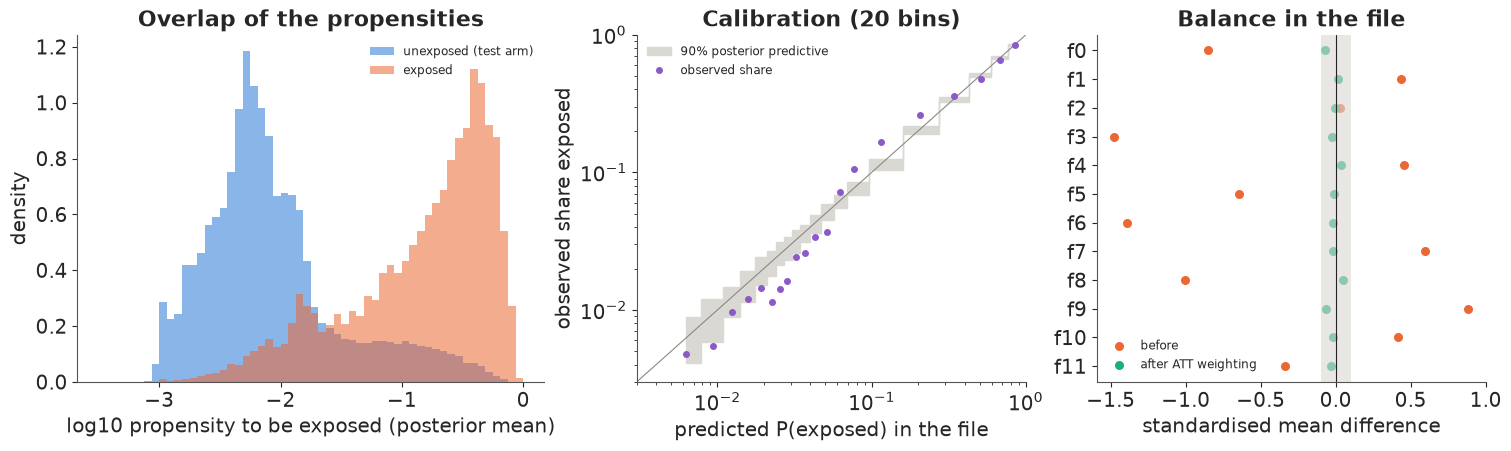

In [15]:
Xs = X[S]


def smd_w(Xm, d, w):
    m1 = Xm[d == 1].mean(0)
    m0 = np.average(Xm[d == 0], axis=0, weights=w)
    sd = np.sqrt((Xm[d == 1].var(0) + Xm[d == 0].var(0)) / 2)
    return (m1 - m0) / sd


bal = pd.DataFrame({"before": smd_w(Xs, Ds, np.ones(ue.sum())), "after weighting": smd_w(Xs, Ds, w_u)}, index=FEATS)
Rs = R[S]
bal["scores, after"] = smd_w(Rs, Ds, w_u)
print(bal.round(3).T.to_string())
print(f"max |SMD| before {bal.before.abs().max():.2f}, after (raw features) {bal['after weighting'].abs().max():.3f}, "
      f"after (normal scores) {bal['scores, after'].abs().max():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.2, 1, 1]})
ax = axes[0]
lb = np.linspace(-3.5, 0, 57)
ax.hist(np.log10(e_pop[ue]), bins=lb, density=True, color=BLUE, alpha=0.55, label="unexposed (test arm)")
ax.hist(np.log10(e_pop[Ds == 1]), bins=lb, density=True, color=ORANGE, alpha=0.55, label="exposed")
ax.set(xlabel="log10 propensity to be exposed (posterior mean)", ylabel="density",
       title="Overlap of the propensities")
ax.legend(fontsize=8.5)
ax = axes[1]
lo, hi = np.percentile(ppc_share, [5, 95], 0)
ax.fill_between(calib.pred, lo, hi, color=LIGHT, step="mid", label="90% posterior predictive")
ax.plot([0, 1], [0, 1], color=MUTED, lw=0.8)
ax.plot(calib.pred, calib.obs, "o", color=PURPLE, ms=4, label="observed share")
ax.set(xscale="log", yscale="log", xlim=(3e-3, 1), ylim=(3e-3, 1), xlabel="predicted P(exposed) in the file",
       ylabel="observed share exposed", title="Calibration (20 bins)")
ax.legend(fontsize=8.5)
ax = axes[2]
ax.scatter(bal.before, yy, color=ORANGE, s=30, label="before")
ax.scatter(bal["after weighting"], yy, color=AQUA, s=30, label="after ATT weighting")
ax.axvspan(-0.1, 0.1, color=LIGHT, alpha=0.6, lw=0)
ax.axvline(0, color=INK, lw=0.8)
ax.set(yticks=yy, yticklabels=FEATS, xlabel="standardised mean difference", title="Balance in the file")
ax.invert_yaxis()
ax.legend(fontsize=8.5);

**The calibration check fails.** In **16 of 20 bins** the observed share lies outside the 90% posterior
predictive band; the model is too low in the middle of the range (around 0.1-0.3) and too high below 0.05, by
up to 5 points. We keep the model anyway for now, because the question is whether the misfit matters for the
answer, and part F tests exactly that with richer models.

**Overlap** is the other check. Positivity requires every exposed user to have comparable unexposed users,
which on the propensity scale means unexposed users with similar propensities. The left panel shows the two
distributions sitting thirty-fold apart: most unexposed mass lies between $10^{-3}$ and $10^{-1.5}$, most
exposed mass between $10^{-1.5}$ and 1, and the exposed's long left tail reaches deep into the unexposed
range. The median exposed user has a population propensity of **0.21**, the median unexposed user
**0.0066**. The overlap is not broken - only 1 of 9,122 exposed users is above 0.9, and the unexposed reach
0.39 at their 99th percentile - but it is thin, and thin overlap is expensive: once
reweighted to look like the exposed, the top 1% of unexposed users carry **28% of the weight**, and the
49,039 unexposed respondents count as **3,736** effective ones.

**Balance** is the check the method is built for, and it passes. Weighting each unexposed respondent by
their odds of exposure brings the largest SMD from **1.47 to 0.074** on the raw features (0.061 on the normal
scores), every feature inside the 0.1 band. By the standard diagnostics of the propensity literature, the
weighted unexposed now look like the exposed. Keep that in mind when we see the estimates.

## E · Four estimates of the effect on the exposed

Every estimator of the effect on the exposed has the same shape: the exposed users' own outcome rate, which we
observe, minus an estimate of the rate they would have had without ads, which we do not:

$$\tau = \bar Y_{D=1} - \widehat{E}\big[Y(0) \mid D = 1\big].$$

They differ in how they build that counterfactual from the unexposed:

- **IPW** weights unexposed respondents by their odds of exposure, $w_i = e(x_i)/(1 - e(x_i))$ (times $1/f$),
  and takes the weighted mean of their outcomes. We do not trim the weights: the unexposed propensities
  stay below about 0.4 at their 99th percentile, so the odds stay bounded.
- **Stratification** cuts the propensity scale into ten bands at the deciles of the exposed and compares
  exposed and unexposed within each band, weighting bands by their exposed counts (Rosenbaum & Rubin 1984).
- **Outcome regression** fits a model $m_0(x)$ of the outcome among the unexposed and averages its
  predictions over the exposed.
- **AIPW** (doubly robust; Robins, Rotnitzky & Zhao 1994) starts from outcome regression and corrects it
  with the weighted residuals of the unexposed: $\hat\tau = \overline{(Y - m_0)}_{D=1} - \sum_{D=0} w_i (Y_i -
  m_0(x_i)) / \sum_{D=0} w_i$. It is consistent if either the propensity or the outcome model is right.

The outcome models are Bayesian logistic regressions with the same 24 terms, fitted to the 49,039 unexposed
respondents of each KPI.

**Propagating uncertainty.** A fully joint Bayesian model of exposure and outcome sounds natural, but it has
a known flaw: the outcome model then feeds back into the propensity coefficients, which start to fit the
outcome instead of the exposure, and the balancing property is lost (McCandless, Gustafson & Austin 2009;
Zigler et al. 2013). The usual answer is a **cut**: fit the propensity model on exposure alone, then push each
of its posterior draws through the estimator. That covers uncertainty about the propensities, but not the
sampling variability of the outcomes themselves, which a plug-in estimator treats as fixed. For that we add
the **Bayesian bootstrap** (Rubin 1981): for each draw, give every respondent an Exponential(1) weight - a
draw from a Dirichlet posterior over the population of respondents. Pairing 400 propensity draws, 400
outcome-model draws and 400 bootstrap weightings gives 400 draws of each estimate. The rows marked "mean
model" hold the propensity and outcome models at their posterior means, to show how much each source
contributes.

In [16]:
def outcome_model(Z, y, name):
    with pm.Model(coords=coords, name=name) as m:
        a = pm.Normal("a", special.logit(max(y.mean(), 1e-3)), 1.5)
        b_lin = pm.Normal("b_lin", 0.0, 0.5, dims="feature")
        b_quad = pm.Normal("b_quad", 0.0, 0.5, dims="feature")
        pm.Bernoulli("y", logit_p=a + Z[:, :12] @ b_lin + Z[:, 12:] @ b_quad, observed=y)
    return m


m0_draws = {}
for k in KPIS:
    t0 = time.time()
    with outcome_model(Zs[ue], Ys[k][ue], k):
        idt = pm.sample(tune=400, draws=500, random_seed=RANDOM_SEED, progressbar=False,
                        nuts={"adaptation": "low_rank"})
    s_ = az.summary(idt, round_to=3)
    print(f"{k:10s} outcome model on {ue.sum():,} unexposed rows: {time.time() - t0:.0f} s, divergences "
          f"{int(idt.sample_stats['diverging'].sum())}, max r_hat {s_['r_hat'].max():.3f}, "
          f"min bulk ESS {s_['ess_bulk'].min():.0f}")
    po = az.extract(idt, var_names=[f"{k}::a", f"{k}::b_lin", f"{k}::b_quad"], num_samples=400,
                    random_seed=RANDOM_SEED + 1)
    Bo = np.concatenate([po[f"{k}::b_lin"].values, po[f"{k}::b_quad"].values], 0)
    m0_draws[k] = special.expit(po[f"{k}::a"].values[None, :] + Zs @ Bo)        # (rows, draws)
    del idt

visit      outcome model on 49,039 unexposed rows: 53 s, divergences 0, max r_hat 1.013, min bulk ESS 4209


conversion outcome model on 49,039 unexposed rows: 46 s, divergences 0, max r_hat 1.010, min bulk ESS 3359


In [17]:
def estimators(y, d, w, m0, g, n_strata=10, e_rank=None):
    """ATT estimates for one draw: w = ATT weights (sample odds), m0 = predicted no-ad outcome,
    g = Bayesian-bootstrap weights over respondents."""
    t, u = d == 1, d == 0
    y1 = np.average(y[t], weights=g[t])
    out = {"naive": y1 - np.average(y[u], weights=g[u])}
    out["IPW"] = y1 - np.average(y[u], weights=g[u] * w[u])
    cuts = np.quantile(e_rank[t], np.linspace(0, 1, n_strata + 1)[1:-1])
    st = np.searchsorted(cuts, e_rank)
    est = tot = 0.0
    for s in range(n_strata):
        a_, b_ = t & (st == s), u & (st == s)
        if b_.any():
            est += g[a_].sum() * (np.average(y[a_], weights=g[a_]) - np.average(y[b_], weights=g[b_]))
            tot += g[a_].sum()
    out["stratification"] = est / tot
    out["outcome regression"] = np.average(y[t] - m0[t], weights=g[t])
    out["AIPW"] = out["outcome regression"] - np.average(y[u] - m0[u], weights=g[u] * w[u])
    out["AIPW baseline"] = y1 - out["AIPW"]           # the imputed no-ad rate of the exposed
    return out


rows = []
for j in range(400):
    g = rng.exponential(size=len(S))                       # Bayesian bootstrap (Rubin 1981)
    for k in KPIS:
        r_ = estimators(Ys[k], Ds, odds_s[:, j], m0_draws[k][:, j], g, e_rank=eta_s[:, j])
        rows += [{"kpi": k, "estimator": e_, "draw": j, "att": v} for e_, v in r_.items()]
    # the same quantities with the propensity draw held at its mean (bootstrap only)
    for k in KPIS:
        r_ = estimators(Ys[k], Ds, w_mean, m0_draws[k].mean(1), g, e_rank=eta_mean)
        rows += [{"kpi": k, "estimator": e_ + " [mean model]", "draw": j, "att": v} for e_, v in r_.items()]
est = pd.DataFrame(rows)
ORDER = ["naive", "IPW", "stratification", "outcome regression", "AIPW"]
tab = est.groupby(["kpi", "estimator"]).att.agg(mean="mean", lo=lambda v: v.quantile(0.05),
                                                 hi=lambda v: v.quantile(0.95), sd="std").reset_index()
for k in KPIS:
    t_ = tab[tab.kpi == k].set_index("estimator").loc[ORDER + [o + " [mean model]" for o in ORDER[1:]]]
    t_["vs truth"] = t_["mean"] - truth[k]
    print(f"--- {k}: experimental truth {truth[k]:.4f}")
    print(t_.drop(columns="kpi").round(4).to_string())

--- visit: experimental truth 0.2117
                                   mean      lo      hi      sd  vs truth
estimator                                                                
naive                            0.3718  0.3632  0.3801  0.0051    0.1601
IPW                              0.2516  0.2373  0.2666  0.0091    0.0399
stratification                   0.2552  0.2429  0.2692  0.0084    0.0435
outcome regression               0.2587  0.2475  0.2713  0.0073    0.0470
AIPW                             0.2605  0.2473  0.2740  0.0080    0.0488
IPW [mean model]                 0.2518  0.2380  0.2662  0.0084    0.0401
stratification [mean model]      0.2556  0.2422  0.2682  0.0081    0.0439
outcome regression [mean model]  0.2587  0.2515  0.2661  0.0043    0.0470
AIPW [mean model]                0.2605  0.2475  0.2735  0.0077    0.0488
--- conversion: experimental truth 0.0278
                                   mean      lo      hi      sd  vs truth
estimator                        

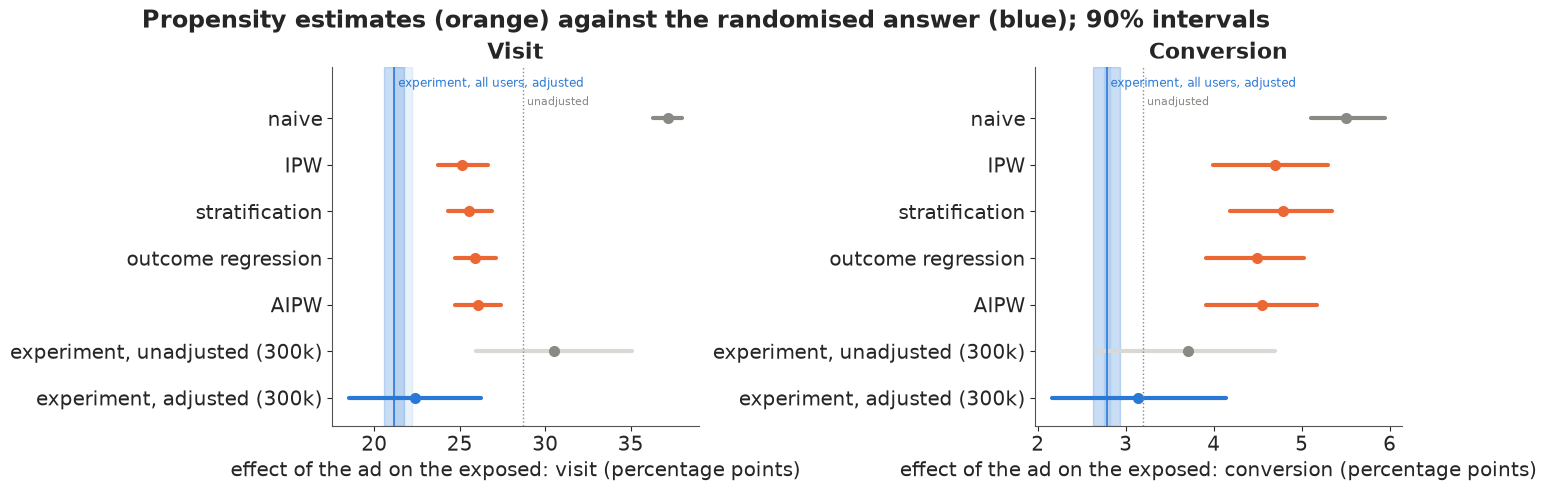

In [18]:
iv_post = {k: idata_iv.posterior["att"].sel(kpi=k).values.ravel() for k in KPIS}
adj_post = {k: rng.normal(exp_s[k]["300k sample"], exp_s[k]["sd (sample)"], 4000) for k in KPIS}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
labels = ORDER + ["experiment, unadjusted (300k)", "experiment, adjusted (300k)"]
for ax, k in zip(axes, KPIS):
    for i, e_ in enumerate(labels):
        if e_.startswith("experiment"):
            v = iv_post[k] if "unadjusted" in e_ else adj_post[k]
        else:
            v = est[(est.kpi == k) & (est.estimator == e_)].att.values
        lo, hi = np.percentile(v, [5, 95])
        col = (LIGHT if "unadjusted" in e_ else BLUE) if e_.startswith("experiment") else (
            MUTED if e_ == "naive" else ORANGE)
        ax.plot([lo * 100, hi * 100], [i, i], color=col, lw=3, solid_capstyle="round")
        ax.plot(v.mean() * 100, i, "o", color=col if col != LIGHT else MUTED, ms=7)
    ax.axvspan((truth[k] - 1.645 * truth_sd[k]) * 100, (truth[k] + 1.645 * truth_sd[k]) * 100, color=BLUE,
               alpha=0.25)
    ax.axvspan(truth_rng[k][0] * 100, truth_rng[k][1] * 100, color=BLUE, alpha=0.1)   # range across bases
    ax.axvline(truth[k] * 100, color=BLUE, lw=1.2)
    ax.axvline(truth_unadj[k] * 100, color=MUTED, lw=1, ls=":")
    ax.text(truth[k] * 100, -0.75, " experiment, all users, adjusted", color=BLUE, fontsize=8.5, va="center")
    ax.text(truth_unadj[k] * 100, -0.35, " unadjusted", color=MUTED, fontsize=8, va="center")
    ax.set(yticks=range(len(labels)), yticklabels=labels, ylim=(len(labels) - 0.4, -1.1),
           xlabel=f"effect of the ad on the exposed: {k} (percentage points)", title=f"{k.capitalize()}")
fig.suptitle("Propensity estimates (orange) against the randomised answer (blue); 90% intervals");

The four estimators agree with each other and disagree with the experiment.

For **visits**, every propensity estimate lands between **25.2 and 26.1 points**, with 90% intervals about
3 points wide; the experiment's benchmark is **21.2**, so they are 4-5 points (19-23%) too high, and none of
their intervals reaches it. For **conversions** they give **4.5-4.8 points** against a benchmark of
**2.78**, 61-72% too high, again with intervals that exclude the truth by a wide margin. The adjustment
removed most of the naive bias for visits (37.2 points) and less of it for conversions (5.5 points). The
experiment run on the same 300,000 users, adjusted as in part B, gives 22.4 and 3.15 with wide intervals that
cover the benchmark; even unadjusted, its intervals are about three times wider than the propensity
intervals for visits and half again as wide for conversions, and centred elsewhere. Against the unadjusted
experimental answer (dotted), the propensity methods would look slightly low for visits and still far too
high for conversions. The darker blue band in this and later figures is the benchmark's sampling
uncertainty only; the lighter one spans the three adjusted bases of part B, a reminder that the answer key
itself is known to about a point for visits.

Most of the posterior width comes from the respondents, not from the models. Holding the propensity model at
its mean barely narrows IPW (sd 0.91 to 0.84 points for visits); holding the outcome model at its mean halves
the width of outcome regression (0.73 to 0.43). Either way, the uncertainty that the Bayesian machinery
propagates is the uncertainty *given* that the features contain every confounder. It says nothing about the
error that matters here.

## F · Why it fails

### F1 · The disagreement lives in one number: what the exposed would have done anyway

In [19]:
p1_file = {k: Ys[k][Ds == 1].mean() for k in KPIS}
base = []
for k in KPIS:
    imp = est[(est.kpi == k) & (est.estimator == "AIPW baseline")].att.values
    base.append({"kpi": k, "exposed, with ads": p1_file[k], "unexposed (naive)": Ys[k][ue].mean(),
                 "propensity (AIPW)": imp.mean(),
                 "experiment, unadjusted": pc1_true[k] - truth_unadj[k],
                 "experiment, adjusted": pc0_true[k]})
base = pd.DataFrame(base).set_index("kpi")
print(base.round(4).to_string())
for k in KPIS:
    print(f"{k:10s}: selection bias of the naive baseline {base.loc[k, 'experiment, adjusted'] - base.loc[k, 'unexposed (naive)']:+.4f}; "
          f"left after propensity adjustment {base.loc[k, 'experiment, adjusted'] - base.loc[k, 'propensity (AIPW)']:+.4f}; "
          f"implied lift: experiment {pc1_true[k] / pc0_true[k]:.2f}x, propensity "
          f"{p1_file[k] / base.loc[k, 'propensity (AIPW)']:.1f}x")

            exposed, with ads  unexposed (naive)  propensity (AIPW)  experiment, unadjusted  experiment, adjusted
kpi                                                                                                              
visit                  0.4062             0.0343             0.1456                  0.1275                0.2028
conversion             0.0563             0.0013             0.0109                  0.0218                0.0260
visit     : selection bias of the naive baseline +0.1685; left after propensity adjustment +0.0573; implied lift: experiment 2.04x, propensity 2.8x
conversion: selection bias of the naive baseline +0.0247; left after propensity adjustment +0.0151; implied lift: experiment 2.07x, propensity 5.2x


Every method agrees on what the exposed did with ads, 40.6% visiting and 5.6% converting in the file. They
disagree only about the counterfactual. The naive comparison uses the unexposed rate, 3.4%; the propensity
methods impute **14.6%**; the adjusted experiment says **20.3%** (12.75% unadjusted). For conversions: 0.13%
naive, **1.09%** propensity, **2.60%** experiment (2.18% unadjusted).

Read as selection bias, the naive baseline is 16.9 points too low for visits; the propensity adjustment
recovers 11.1 of them and leaves **5.7**. For conversions the naive baseline is 2.5 points too low, and the
adjustment recovers only 1.0 of them, leaving **1.5**, which is why the conversion estimate is so much worse
in relative terms. In the units a brand lift report uses, the propensity analysis says exposure made people
**2.8 times** as likely to visit and **5.2 times** as likely to convert; the experiment says about **2.0
times** for both.

The features capture who gets an ad well enough to balance them, and they capture activity well enough to
remove most of the visit bias. What they do not capture is **intent**: whether a person was about to buy
anyway. Criteo is a retargeting platform, so exposed users are likely people who recently showed interest,
and that interest is visible to the ad platform's bidding but probably only partly in twelve anonymised
features. A conversion is a sharper measure
of intent than a visit, so the hidden part matters more for it.

### F2 · More features move the answer, and nothing says when to stop

An analyst who suspects missing confounders adds features. We add them one at a time, most imbalanced
first, refitting both models (posterior modes this time, with the same priors) and recomputing AIPW, and we
also try random subsets of features, a model without the squares, and one with all 66 pairwise
interactions.

In [20]:
def aipw_map(Z, d, ys, w_scale=1.0, prior_sd=0.5):
    """AIPW (Hajek form) with posterior-mode propensity and outcome models; returns {kpi: att}."""
    bp = fit_map(Z, d, prior_sd=prior_sd, a0=special.logit(d.mean()))
    Z1 = np.column_stack([np.ones(len(Z)), Z])
    eta = Z1 @ bp
    w = np.exp(eta - eta[d == 0].max()) * w_scale                 # weights enter only normalised averages
    t, u = d == 1, d == 0
    out = {}
    for k, y in ys.items():
        bo = fit_map(Z[u], y[u], prior_sd=prior_sd, a0=special.logit(max(y[u].mean(), 1e-4)))
        m0 = special.expit(Z1 @ bo)
        out[k] = np.mean(y[t] - m0[t]) - np.average(y[u] - m0[u], weights=w[u])
    return out


def design(cols, quad=True):
    return Zs[:, list(cols) + ([12 + c for c in cols] if quad else [])] if cols else np.zeros((len(S), 0))


order = list(np.argsort(-np.abs(smd["exposed vs unexposed"].values)))
t0 = time.time()
path = [{"k": 0, **{k: base.loc[k, "exposed, with ads"] - base.loc[k, "unexposed (naive)"] for k in KPIS}}]
for i in range(1, 13):
    path.append({"k": i, **aipw_map(design(order[:i]), Ds, Ys)})
path = pd.DataFrame(path)
path["added"] = ["-"] + [FEATS[c] for c in order]
cloud = []
for kk in (2, 4, 6, 8, 10):
    for r_ in range(8):
        cols = sorted(rng.choice(12, kk, replace=False))
        cloud.append({"k": kk, **aipw_map(design(cols), Ds, Ys)})
cloud = pd.DataFrame(cloud)
lin_only = aipw_map(design(range(12), quad=False), Ds, Ys)
pairs = np.column_stack([Zs[:, i] * Zs[:, j] for i, j in itertools.combinations(range(12), 2)])
pairs = (pairs - pairs.mean(0)) / pairs.std(0)
inter = aipw_map(np.column_stack([Zs, pairs]), Ds, Ys)


def calib_misses(Z):
    """Bins (of 20) where the observed exposed share is outside +-1.645 binomial sd of the predicted one."""
    eta_ = np.column_stack([np.ones(len(Z)), Z]) @ fit_map(Z, Ds, a0=special.logit(Ds.mean()))
    p_ = special.expit(eta_)
    b_ = pd.qcut(p_, 20, labels=False, duplicates="drop")
    c_ = pd.DataFrame({"p": p_, "d": Ds}).groupby(b_).agg(p=("p", "mean"), d=("d", "mean"), n=("d", "size"))
    return int(np.sum(np.abs(c_.d - c_.p) > 1.645 * np.sqrt(c_.p * (1 - c_.p) / c_.n)))


print(f"calibration misses (of 20 bins): squares model {calib_misses(Zs)}, "
      f"with interactions {calib_misses(np.column_stack([Zs, pairs]))}")
print(f"{len(path) + len(cloud) + 2} specifications in {time.time() - t0:.0f} s")
print(path.round(4).to_string(index=False))
print("random feature subsets (AIPW), min-max by size:")
print(cloud.groupby("k").agg(["min", "max"]).round(4).to_string())
print(f"all 12, linear terms only: {pd.Series(lin_only).round(4).to_dict()}")
print(f"all 12 + squares + 66 pairwise interactions: {pd.Series(inter).round(4).to_dict()}")

calibration misses (of 20 bins): squares model 16, with interactions 10
55 specifications in 8 s
 k  visit  conversion added
 0 0.3719      0.0551     -
 1 0.3301      0.0529    f3
 2 0.3448      0.0601    f6
 3 0.2731      0.0503    f8
 4 0.2635      0.0504    f9
 5 0.2641      0.0497    f0
 6 0.2649      0.0502    f5
 7 0.2648      0.0503    f7
 8 0.2639      0.0458    f4
 9 0.2639      0.0460    f1
10 0.2642      0.0458   f10
11 0.2636      0.0461   f11
12 0.2600      0.0455    f2
random feature subsets (AIPW), min-max by size:
     visit         conversion        
       min     max        min     max
k                                    
2   0.2530  0.3669     0.0437  0.0512
4   0.2721  0.3173     0.0465  0.0545
6   0.2502  0.2714     0.0439  0.0493
8   0.2523  0.2853     0.0439  0.0471
10  0.2593  0.2663     0.0439  0.0468
all 12, linear terms only: {'visit': 0.2829, 'conversion': 0.045}
all 12 + squares + 66 pairwise interactions: {'visit': 0.2582, 'conversion': 0.0443}


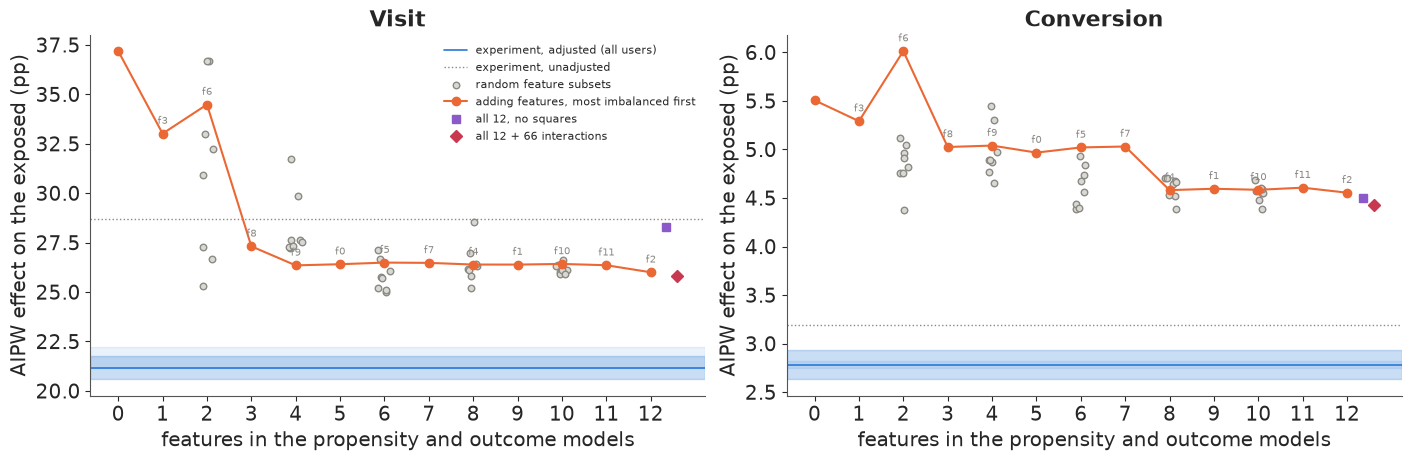

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, k in zip(axes, KPIS):
    ax.axhspan((truth[k] - 1.645 * truth_sd[k]) * 100, (truth[k] + 1.645 * truth_sd[k]) * 100, color=BLUE,
               alpha=0.25)
    ax.axhspan(truth_rng[k][0] * 100, truth_rng[k][1] * 100, color=BLUE, alpha=0.1)   # range across bases
    ax.axhline(truth[k] * 100, color=BLUE, lw=1.2, label="experiment, adjusted (all users)")
    ax.axhline(truth_unadj[k] * 100, color=MUTED, lw=1, ls=":", label="experiment, unadjusted")
    ax.scatter(cloud.k + rng.uniform(-0.15, 0.15, len(cloud)), cloud[k] * 100, color=LIGHT, edgecolor=MUTED, s=22,
               label="random feature subsets")
    ax.plot(path.k, path[k] * 100, "o-", color=ORANGE, label="adding features, most imbalanced first")
    ax.plot([12.35], [lin_only[k] * 100], "s", color=PURPLE, label="all 12, no squares")
    ax.plot([12.6], [inter[k] * 100], "D", color=RED, label="all 12 + 66 interactions")
    for i, r_ in path.iterrows():
        if i:
            ax.annotate(r_.added, (r_.k, r_[k] * 100), textcoords="offset points", xytext=(0, 7), fontsize=7,
                        ha="center", color=MUTED)
    ax.set(xlabel="features in the propensity and outcome models", ylabel="AIPW effect on the exposed (pp)",
           title=k.capitalize(), xticks=range(13))
axes[0].legend(fontsize=8, loc="upper right");

The ladder tells the usual story at first. Adding f3, the most imbalanced feature, moves the visit estimate from
37.2 to 33.0 points; adding f8 as the third brings it to 27.3; from four features on it sits between 26.0 and
26.5 and stays there. The random subsets spread widely with two features (25.3-36.7 points) and close in as
features are added. An analyst watching this would see the estimate **converge** and stop, reasonably. It
converges to the wrong place: the benchmark is 21.2, and none of the 55 specifications comes within 3.8 points
of it - the lowest is 25.0. On the way down the ladder crosses the *unadjusted* experimental answer at three
features, which shows the other danger: had that been the truth, a three-feature model would have looked
nearly right by luck.

Flexibility does not help either. Dropping the squares gives 28.3; adding all 66 pairwise interactions gives
25.8, and the interactions reduce the calibration failure of part D (bins outside the band fall from 16 to
10) while moving the estimate by 0.2 points. A better model of who gets an ad is not a better model of what
they would have done without one.

Conversions show the same pattern more starkly: every specification lies between **4.4 and 6.0 points**
against a benchmark of 2.78. The features that finish the visit adjustment have almost nothing left to say
about purchase intent. Nothing in the observational data marks the right number of features, because the
quantity that would tell us - the exposed users' no-ad outcome - is exactly what is missing.

## G · How strong would the hidden confounder have to be?

A sensitivity analysis asks how much unmeasured confounding it would take to change the conclusion. The
simplest version is the **E-value** (VanderWeele & Ding 2017): for an observed risk ratio $RR > 1$,

$$E = RR + \sqrt{RR\,(RR - 1)}$$

is the strength (as a risk ratio with both exposure and outcome) that an unmeasured confounder would need,
above and beyond the measured features, to explain the association away. We can also ask what it takes to move
the propensity estimate to the experiment's: divide the two risk ratios and compute the E-value of the ratio.

The second version builds the bias into the model. Let the true no-ad rate of the exposed differ from the
propensity-imputed one by a log odds ratio $\delta$:

$$\operatorname{logit} q_{\text{true}} = \operatorname{logit} q_{\text{imputed}} + \delta, \qquad \tau =
p_1 - q_{\text{true}}.$$

The observational data say nothing about $\delta$ - the exposed's counterfactual is never observed - so its
posterior is its prior. We fit the model in PyMC with the imputed rate entering as a noisy measurement
(its posterior mean and sd from part E), the exposed rate from its binomial counts, and four priors for
$\delta$ with standard deviations 0.1, 0.25, 0.5 and 1.

In [22]:
def e_value(rr):
    rr = np.where(rr < 1, 1 / rr, rr)
    return rr + np.sqrt(rr * (rr - 1))


for k in KPIS:
    rr_obs = p1_file[k] / base.loc[k, "propensity (AIPW)"]
    rr_true = pc1_true[k] / pc0_true[k]
    print(f"{k:10s}: risk ratio, propensity {rr_obs:.2f}; E-value to explain it away {e_value(rr_obs):.1f}; "
          f"bias factor separating it from the experiment {rr_obs / rr_true:.2f} -> E-value {e_value(rr_obs / rr_true):.2f}")

visit     : risk ratio, propensity 2.79; E-value to explain it away 5.0; bias factor separating it from the experiment 1.37 -> E-value 2.07
conversion: risk ratio, propensity 5.18; E-value to explain it away 9.8; bias factor separating it from the experiment 2.50 -> E-value 4.44


imputed no-ad rate of the exposed, logit scale: mean [-1.771 -4.545], sd [0.056 0.275]


divergences 0
delta that would reconcile the propensity estimate with the experiment: {'visit': 0.4, 'conversion': 0.92}
 prior sd of delta        kpi   mean      5%    95%  covers truth
              0.10      visit 0.2607  0.2349 0.2844         False
              0.10 conversion 0.0452  0.0383 0.0512         False
              0.25      visit 0.2613  0.2053 0.3069          True
              0.25 conversion 0.0447  0.0358 0.0520         False
              0.50      visit 0.2596  0.1448 0.3417          True
              0.50 conversion 0.0429  0.0272 0.0528          True
              1.00      visit 0.2662  0.0579 0.3750          True
              1.00 conversion 0.0342 -0.0128 0.0542          True
posterior sd of delta at prior sd 1.0: [0.849 0.923] (the data never see it)


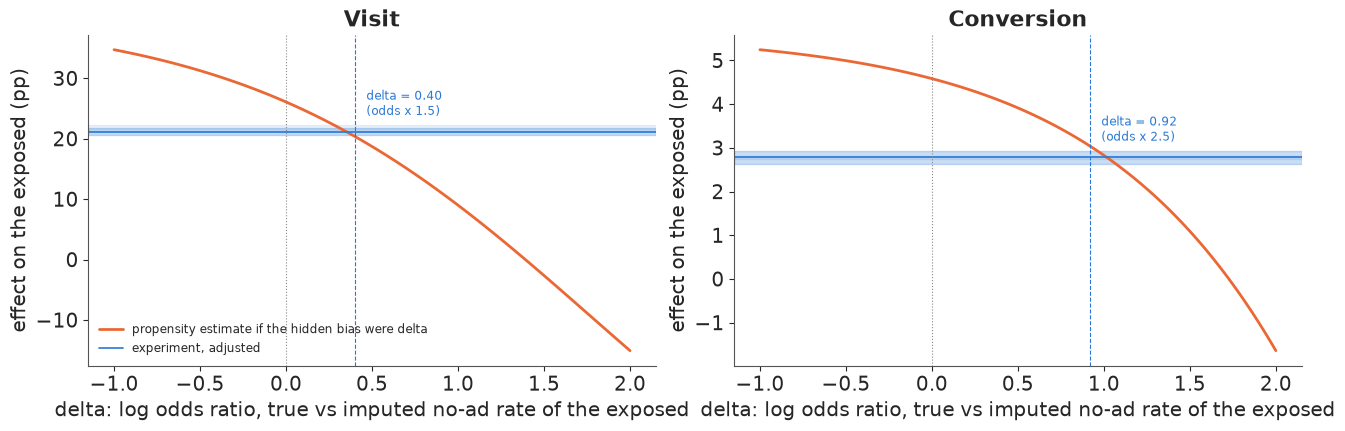

In [23]:
q_imp = {k: est[(est.kpi == k) & (est.estimator == "AIPW baseline")].att.values for k in KPIS}
lq_mu = np.array([special.logit(q_imp[k]).mean() for k in KPIS])
lq_sd = np.array([special.logit(q_imp[k]).std() for k in KPIS])
print(f"imputed no-ad rate of the exposed, logit scale: mean {lq_mu.round(3)}, sd {lq_sd.round(3)}")
n1 = int(Ds.sum())
y1 = np.array([int(Ys[k][Ds == 1].sum()) for k in KPIS])
SCALES = [0.1, 0.25, 0.5, 1.0]
with pm.Model(coords={"kpi": KPIS, "scale": [str(s) for s in SCALES]}) as sens:
    p1 = pm.Beta("p1", 1.0, 1.0, dims="kpi")
    pm.Binomial("y1", n=n1, p=p1, observed=y1, dims="kpi")
    lq = pm.Normal("logit_q", -3.0, 2.0, dims=("scale", "kpi"))          # true no-ad rate of the exposed
    delta = pm.Normal("delta", 0.0, np.array(SCALES)[:, None], dims=("scale", "kpi"))
    pm.Normal("imputed", mu=lq - delta, sigma=lq_sd, observed=np.tile(lq_mu, (len(SCALES), 1)), dims=("scale", "kpi"))
    pm.Deterministic("att", p1 - pm.math.invlogit(lq), dims=("scale", "kpi"))
    idata_sens = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
print(f"divergences {int(idata_sens.sample_stats['diverging'].sum())}")
att_s = idata_sens.posterior["att"]
need = {k: special.logit(pc0_true[k]) - lq_mu[i] for i, k in enumerate(KPIS)}
print("delta that would reconcile the propensity estimate with the experiment:",
      {k: round(float(v), 2) for k, v in need.items()})
sens_tab = []
for s in SCALES:
    for k in KPIS:
        v = att_s.sel(scale=str(s), kpi=k).values.ravel()
        lo, hi = np.percentile(v, [5, 95])
        sens_tab.append({"prior sd of delta": s, "kpi": k, "mean": v.mean(), "5%": lo, "95%": hi,
                         "covers truth": lo <= truth[k] <= hi})
print(pd.DataFrame(sens_tab).round(4).to_string(index=False))
dp = idata_sens.posterior["delta"].sel(scale="1.0")
print(f"posterior sd of delta at prior sd 1.0: {dp.std(('chain', 'draw')).values.round(3)} (the data never see it)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
dg = np.linspace(-1.0, 2.0, 121)
for i, (ax, k) in enumerate(zip(axes, KPIS)):
    curve = p1_file[k] - special.expit(lq_mu[i] + dg)
    ax.plot(dg, curve * 100, color=ORANGE, lw=2, label="propensity estimate if the hidden bias were delta")
    ax.axhspan((truth[k] - 1.645 * truth_sd[k]) * 100, (truth[k] + 1.645 * truth_sd[k]) * 100, color=BLUE,
               alpha=0.25)
    ax.axhspan(truth_rng[k][0] * 100, truth_rng[k][1] * 100, color=BLUE, alpha=0.1)   # range across bases
    ax.axhline(truth[k] * 100, color=BLUE, lw=1.2, label="experiment, adjusted")
    ax.axvline(0, color=MUTED, lw=0.8, ls=":")
    ax.axvline(need[k], color=BLUE, lw=0.8, ls="--")
    ax.annotate(f"delta = {need[k]:.2f}\n(odds x {np.exp(need[k]):.1f})", (need[k], truth[k] * 100),
                textcoords="offset points", xytext=(8, 12), fontsize=8.5, color=BLUE)
    ax.set(xlabel="delta: log odds ratio, true vs imputed no-ad rate of the exposed",
           ylabel="effect on the exposed (pp)", title=k.capitalize())
axes[0].legend(fontsize=8.5, loc="lower left");

The E-values are large in one sense and small in another. To explain the whole conversion association away, a
hidden confounder would need risk ratios of **9.8** with both exposure and conversion; for visits, **5.0**.
Nobody should conclude the ads did nothing. But to move the propensity estimate to the experiment's answer
takes much less: an E-value of **2.1** for visits and **4.4** for conversions. In the bias model the gap is
$\delta = 0.40$ for visits and **0.92** for conversions: the exposed's true no-ad odds of converting are 2.5
times what the propensity model imputes. "Intent to buy" in a retargeting campaign is easily that strong.
The figure draws the whole curve: the estimate falls steadily as $\delta$ grows and crosses the benchmark at
those two values.

The posterior of $\delta$ is essentially its prior (sd 0.85 and 0.92 against 1.0; the prior on the true rate trims
the tails), which is the formal way of saying the data cannot learn it. Its prior therefore sets
the width of the answer. With a prior sd of 0.1 - a near-certain belief that the features caught everything -
neither interval covers the benchmark. Covering it takes a prior sd of 0.25 for visits (interval 20.5-30.7
points) and 0.5 for conversions (2.7-5.3). The honest observational report is then an interval two to four
times as wide as the propensity analysis printed (about 10 points against 2.7 for visits, 2.6 against 1.3
for conversions), and how wide is a matter of opinion about $\delta$ that
only an experiment can settle. Gordon et al. (2019) found that the size of the bias varied widely from campaign
to campaign; that is the same finding from the other side.

## H · Survey-sized samples: noisy and right, or tight and wrong

So far we have used hundreds of thousands of users. A real brand lift survey has a few thousand respondents.
To see what happens at that size we **replay** the study: draw a simple random sample of $n$ users from the
300,000 (respondents of both arms), run both analyses on it, and repeat 100 times for each of $n$ = 2,000,
6,000, 20,000 and 60,000. The experimental analysis is the adjusted Wald estimate of part B (with linear terms
only, fitted on the survey's control respondents), with a large-sample sd; the observational one is AIPW on the
survey's test respondents with posterior-mode models, with the usual influence-function sd that treats the
fitted models as known. Surveys of 60,000 are a fifth of the pool, so replays overlap and their spread is
slightly understated.

In [24]:
def replay(n, rng_):
    idx = rng_.choice(N, n, replace=False)
    c_, t_ = idx[T[idx] == 0], idx[T[idx] == 1]
    out = {"n": n}
    Zc1, Zt1 = Zb[c_, :13], Zb[t_, :13]
    e_t = D[t_].mean()
    for k in KPIS:
        att, sd, _, _ = wald(len(c_), Y[k][c_].sum(), len(t_), D[t_].sum(), Y[k][t_].sum())
        out[f"wald_{k}"], out[f"wald_sd_{k}"] = att, sd
        # adjusted as in B3, linear terms only (squares made a few small surveys explode), fitted on the
        # survey's control respondents
        bc = np.linalg.lstsq(Zc1, Y[k][c_], rcond=None)[0]
        r_t = Y[k][t_] - Zt1 @ bc
        r_c = Y[k][c_] - Zc1 @ bc
        att = r_t.mean() / e_t
        out[f"rct_{k}"] = att
        out[f"rct_sd_{k}"] = np.sqrt(np.var(r_t - D[t_] * att) / len(t_) + np.var(r_c) / len(c_)) / e_t
    Z, d = Zall[t_], D[t_]
    bp = fit_map(Z, d, a0=special.logit(max(d.mean(), 1e-3)))
    Z1 = np.column_stack([np.ones(len(Z)), Z])
    eta = Z1 @ bp
    w = np.exp(eta - eta[d == 0].max())
    tt, uu = d == 1, d == 0
    for k in KPIS:
        y = Y[k][t_]
        bo = fit_map(Z[uu], y[uu], a0=special.logit(max(y[uu].mean(), 1e-4)))
        m0 = special.expit(Z1 @ bo)
        att = np.mean(y[tt] - m0[tt]) - np.average(y[uu] - m0[uu], weights=w[uu])
        # influence-function sd (nuisance models treated as known)
        mu_w = np.average(y[uu] - m0[uu], weights=w[uu])
        phi = (tt * (y - m0 - (att + mu_w)) - uu * w * (y - m0 - mu_w) * tt.sum() / w[uu].sum()) / tt.mean()
        out[f"ps_{k}"], out[f"ps_sd_{k}"] = att, phi.std() / np.sqrt(len(y))
    return out


SIZES, REPS = [2_000, 6_000, 20_000, 60_000], 100
t0 = time.time()
rr = np.random.default_rng(RANDOM_SEED + 7)
reps = pd.DataFrame([replay(n, rr) for n in SIZES for _ in range(REPS)])
print(f"{len(reps)} replays in {time.time() - t0:.0f} s")
z90 = stats.norm.ppf(0.95)
summ_rep = []
for n in SIZES:
    r_ = reps[reps.n == n]
    for meth in ("wald", "rct", "ps"):
        for k in KPIS:
            v, s = r_[f"{meth}_{k}"], r_[f"{meth}_sd_{k}"]
            summ_rep.append({"n": n, "design": {"wald": "experiment, unadjusted", "rct": "experiment, adjusted",
                                                "ps": "propensity (AIPW)"}[meth],
                             "kpi": k, "mean": v.mean(), "sd across surveys": v.std(), "median stated sd": s.median(),
                             "90% coverage": np.mean(np.abs(v - truth[k]) <= z90 * s),
                             "coverage with the true spread": np.mean(np.abs(v - truth[k]) <= z90 * v.std())})
summ_rep = pd.DataFrame(summ_rep)
print(summ_rep.round(4).to_string(index=False))

400 replays in 31 s
    n                 design        kpi   mean  sd across surveys  median stated sd  90% coverage  coverage with the true spread
 2000 experiment, unadjusted      visit 0.2731             0.3706            0.3529          0.87                           0.91
 2000 experiment, unadjusted conversion 0.0227             0.0921            0.0486          0.77                           0.92
 2000   experiment, adjusted      visit 0.2010             0.3410            0.2961          0.82                           0.91
 2000   experiment, adjusted conversion 0.0254             0.0972            0.0471          0.72                           0.93
 2000      propensity (AIPW)      visit 0.2643             0.0712            0.0656          0.74                           0.79
 2000      propensity (AIPW) conversion 0.0467             0.0336            0.0305          0.89                           0.85
 6000 experiment, unadjusted      visit 0.3044             0.1798            

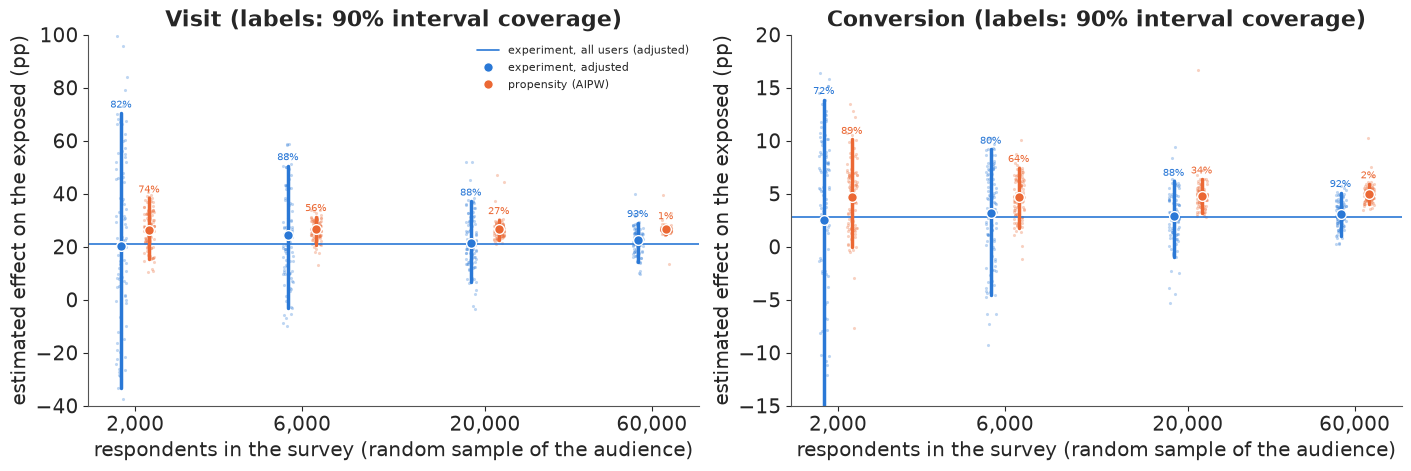

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, k in zip(axes, KPIS):
    ax.axhline(truth[k] * 100, color=BLUE, lw=1.2, label="experiment, all users (adjusted)")
    for meth, col, dx, lab in [("rct", BLUE, -0.04, "experiment, adjusted"), ("ps", ORANGE, 0.04, "propensity (AIPW)")]:
        for n in SIZES:
            v = reps[reps.n == n][f"{meth}_{k}"].values * 100
            x = np.log10(n) + dx
            ax.scatter(np.full(len(v), x) + rng.uniform(-0.015, 0.015, len(v)), v, s=5, color=col, alpha=0.3, lw=0)
            ax.plot([x, x], np.percentile(v, [5, 95]), color=col, lw=2.5)
            ax.plot(x, v.mean(), "o", color=col, ms=7, mec="white", label=lab if n == SIZES[0] else None)
            cov = summ_rep[(summ_rep.n == n) & (summ_rep.kpi == k) & (summ_rep.design == (
                "experiment, adjusted" if meth == "rct" else "propensity (AIPW)"))]["90% coverage"].iloc[0]
            ax.annotate(f"{cov:.0%}", (x, np.percentile(v, 95)), textcoords="offset points", xytext=(0, 4),
                        fontsize=7.5, ha="center", color=col)
    lim = {"visit": (-40, 100), "conversion": (-15, 20)}[k]
    ax.set(xticks=np.log10(SIZES), xticklabels=[f"{n:,}" for n in SIZES], ylim=lim,
           xlabel="respondents in the survey (random sample of the audience)",
           ylabel="estimated effect on the exposed (pp)", title=f"{k.capitalize()} (labels: 90% interval coverage)")
axes[0].legend(fontsize=8, loc="upper right");

The figure is the notebook's argument in one picture. The **experiment** (blue) is noisy and centred: its
replays average 20.1, 24.4, 21.6 and 22.4 points for visits as the survey grows from 2,000 to 60,000
respondents, and 2.5-3.2 points for conversions, around benchmarks of 21.2 and 2.78. At 2,000 respondents it is
nearly useless - the middle 90% of replays runs from about -34 to +71 points for visits - but its intervals know
it: they cover the benchmark in 82-93% of visit replays. For conversions at small sizes coverage falls to 72-80%
because the large-sample sd is too optimistic with a handful of converters in control (4.7 points stated
against 9.7 observed at 2,000); by 20,000 it is back near 90%.

The **propensity** analysis (orange) is tight and wrong, and it does not get less wrong. Its replays average
26.4-26.6 points for visits and 4.7-5.0 for conversions at every size. More respondents only shrink the spread,
from 7.1 to 2.2 points for visits, around the same wrong centre, so coverage collapses: **74%, 56%, 27% and 1%**
for visits and **89%, 64%, 34% and 2%** for conversions. Its stated sds are also too small at the larger sizes
(they ignore the fitting of the two models), but even intervals built from the true spread would cover only 5%
and 10% of replays at 60,000. This is bias, not noise.

At a few thousand respondents the propensity estimate actually looks better: its error is smaller than the
experiment's noise. A brand manager choosing by interval width alone would pick it every time. The difference is
that more data fixes the experiment and cannot fix the propensity analysis. (The unadjusted experiment, in the
table, shows this file's imbalance in miniature: centred near 27-30 points for visits, with coverage down to
62% at 60,000.)

The experiment's noise at survey size is a design problem with a design solution. An intent-to-treat survey
compares everyone in test with everyone in control, and 96% of both are people the campaign never reached,
adding noise and no signal. Below, one survey of 6,000 respondents run through the Bayesian IV model of part B,
and then the standard deviation the same survey would have if it compared only the exposed with the control
users who *would* have been exposed.

In [26]:
surv = rng.choice(N, 6_000, replace=False)
with iv_model(counts(surv[T[surv] == 0], surv[T[surv] == 1])):
    idata_iv_s = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
print(f"one survey of 6,000: divergences {int(idata_iv_s.sample_stats['diverging'].sum())}")
print(az.summary(idata_iv_s, var_names=["att", "p_c0"], ci_prob=0.9, round_to=4))

ghost = []
for n in SIZES:
    for k in KPIS:
        p1_, p0_ = pc1_true[k], pc0_true[k]
        sd_g = np.sqrt(p1_ * (1 - p1_) / (n / 2) + p0_ * (1 - p0_) / (n / 2))
        sd_itt = summ_rep[(summ_rep.n == n) & (summ_rep.kpi == k) & (summ_rep.design == "experiment, adjusted")][
            "sd across surveys"].iloc[0]
        ghost.append({"n": n, "kpi": k, "ITT design sd": sd_itt, "ghost-ad design sd": sd_g, "ratio": sd_itt / sd_g})
print(pd.DataFrame(ghost).round(4).to_string(index=False))

one survey of 6,000: divergences 0
                    mean      sd  eti90_lb  eti90_ub   ess_bulk   ess_tail   r_hat  mcse_mean  mcse_sd
att[visit]        0.3020  0.1059    0.0967    0.4344  4805.5278  2808.3365  1.0002     0.0014   0.0019
att[conversion]  -0.0168  0.0483   -0.1094    0.0392  4607.0748  2846.6413  1.0009     0.0007   0.0011
p_c0[visit]       0.1132  0.0991    0.0064    0.3137  3811.8114  2225.2731  1.0005     0.0014   0.0019
p_c0[conversion]  0.0562  0.0467    0.0052    0.1442  2841.9345  1548.4712  1.0006     0.0007   0.0012
    n        kpi  ITT design sd  ghost-ad design sd   ratio
 2000      visit         0.3410              0.0201 16.9595
 2000 conversion         0.0972              0.0087 11.1411
 6000      visit         0.1705              0.0116 14.6850
 6000 conversion         0.0456              0.0050  9.0463
20000      visit         0.1041              0.0064 16.3666
20000 conversion         0.0249              0.0028  9.0143
60000      visit         0.048

One survey of 6,000 respondents gives a visit effect of 30 points with a 90% interval of 10-43, and a
conversion effect of -1.7 points (-10.9 to 3.9): a survey that cannot tell whether the ads helped or hurt
sales. That is the intent-to-treat design at survey size.

A **ghost-ad** design (Johnson, Lewis & Nubbemeyer 2017) fixes the comparison rather than the sample size.
The ad platform runs its auction for control users too and logs when it *would* have shown the ad, so the
control users who would have been exposed are known, and the survey can be split between exposed test users
and their would-be-exposed controls. With the benchmark rates (41.5% vs 20.3% for visits, 5.4% vs 2.6% for
conversions) and the respondents split evenly, the standard deviation of the effect on the exposed is **8-17
times smaller** than the intent-to-treat design's: at 6,000 respondents, 1.2 points instead of 17 for visits,
0.5 instead of 4.6 for conversions. The table is a calculation, not a replay - Criteo's file does not record
ghost impressions - but it shows the scale of what a better control group buys.

## I · What the brand manager should report

The brand manager asked whether the ads worked. Here is what each analysis would have told them.

The **naive** survey comparison says exposure raised visits by 38 points and conversions by 5.3 points, lifts
of 12 and 45 times. It is not an estimate of anything causal.

The **propensity-adjusted** study, done by the book - a Bayesian model with clean sampling, balance within
0.1 on every feature, four estimators that agree, uncertainty propagated - reports **26 points and 4.5
points**, lifts of 2.8 and 5.2 times, with tight intervals. It overstates both, and the conversion lift by more than double.
The one diagnostic that failed, calibration, did not point to the bias: improving it barely moved the
estimate.

The **experiment** reports **21 points and 2.8 points**, lifts of about 2.0 times, once the arms' small
imbalance is adjusted for. Its own lesson is smaller but real: even a randomised file needs a balance check.

So the report should be built on the holdout: the campaign raised the exposed users' visit rate from about 20%
to 41% and their conversion rate from about 2.6% to 5.4% in this file, roughly a doubling. The propensity
numbers should not appear in it, not even as a cross-check, because agreement between observational estimators
says nothing about their shared bias.

For the next study the design matters more than the analysis. **Keep a randomised holdout**, even a small
one: it is what turned this notebook from guesswork into a measurement. **Survey the right control
respondents**: an intent-to-treat survey wastes 96% of its sample on people the campaign never reached, so it
needs hundreds of thousands of respondents to say anything. A **ghost-ad** or PSA design (Johnson, Lewis &
Nubbemeyer 2017) records which control users *would* have been shown the ad, so the survey can compare the
exposed with their randomised counterparts directly, and part H shows that buys an 8-17 fold reduction in
the experiment's standard deviation at the same number of respondents. If no holdout is possible at all, report
the observational estimate with a sensitivity interval for $\delta$, and calibrate that interval on past
campaigns that did have a holdout.

In [27]:
print(f"total run time {time.time() - T_START:.0f} s")

total run time 239 s


## Summary

- **The naive exposed-versus-unexposed comparison is selection, not lift.** Exposed users visited at 41.5% and
  unexposed at 3.5% (11.9 times); the experiment says the exposed would have visited at about 20% anyway. The
  campaign delivers ads to users who would visit regardless: at most 1% of the least active half were exposed,
  15% of the most active decile.
- **The experiment needed checking too.** The arms of this assembled public file differ by up to 0.05 standard
  deviations on features tied to exposure, far beyond chance with 14 million users. Regression adjustment from
  sufficient statistics moved the effect on the exposed from 28.7 to **21.2 points** (visits) and from 3.20 to
  **2.78 points** (conversions); the choice of basis moves it by about one point.
- **A propensity analysis done by the book overstated both effects.** A Bayesian propensity model with clean
  sampling, balance within 0.074 on every feature, and four estimators that agree (IPW, stratification, outcome
  regression, AIPW) gave **25-26 points** for visits (20% high) and **4.5-4.8 points** for conversions (60-70%
  high), with intervals that exclude the benchmark. That holds for conversions against either benchmark; for
  visits only once the experiment's arm imbalance is adjusted for (against the unadjusted 28.7 the propensity
  estimate would look 10% low). Its calibration check failed, but improving it (16 to 10 bins outside the
  band) moved the estimate by 0.2 points.
- **The whole error is in the imputed baseline.** Propensity methods imputed a no-ad rate of 14.6% for visits
  and 1.1% for conversions; the experiment says 20.3% and 2.6%. As brand lift, that is 2.8 and 5.2 times
  against about 2.0 for both.
- **More features converge to the wrong answer.** Fifty-five specifications gave 25.0-37.2 points for visits
  and 4.4-6.0 for conversions; from four features on the visit estimate stopped moving, 5 points above the
  benchmark. Nothing in the observational data signals when the confounders are all in.
- **The hidden bias is plausible and unlearnable.** Closing the gap takes a confounder with an E-value of 2.1
  (visits) and 4.4 (conversions), or a log odds ratio of 0.40 and 0.92 in the bias model, whose posterior equals
  its prior; covering the benchmark needs prior sds of 0.25 and 0.5, making the honest interval several times
  wider.
- **At survey size the experiment is noisy and right; propensity is tight and wrong.** Over 100 replayed
  surveys per size, adjusted experimental intervals covered the benchmark 72-93% of the time; propensity
  intervals covered it 74-89% at 2,000 respondents and 1-2% at 60,000, because their bias (about 5 points for
  visits) does not shrink. A ghost-ad control group would cut the experiment's sd 8-17 fold at the same size
  (a calculation, not a replay).

## Try it yourself

1. **Choose features like a survey vendor.** A brand lift file usually carries a handful of demographic
   attributes, not behavioural ones. Rerun the AIPW analysis with only the three features that predict
   exposure least (f2, f11 and f10 by the SMDs in part C) and compare the gap with the benchmark. Which KPI's
   estimate moves more, and why?
2. **Joint versus cut.** Fit the propensity and visit-outcome models in one PyMC model, with the AIPW estimate
   as a Deterministic, and compare its posterior with the cut two-stage one in part E. Do the propensity
   coefficients move, and does balance after weighting get worse?
3. **Calibrate the bias prior.** Treat the visit KPI as a "past campaign with a holdout": use its gap,
   $\delta = 0.40$, to set the prior sd for $\delta$ on the conversion KPI, and check whether the resulting
   interval covers the conversion benchmark. How many past campaigns would you want before trusting such a
   prior, given Gordon et al.'s finding that the bias varies widely between campaigns?